In [111]:
import pandas as pd

In [112]:
df = pd.read_csv(
    "Numero_Personas.csv"
)
df.head()

,CCAA,1 de enero de 2025,1 de enero de 2024,1 de enero de 2023,1 de enero de 2022,1 de enero de 2021,1 de enero de 2020,1 de enero de 2019,1 de enero de 2018,1 de enero de 2017,...,1 de enero de 2011,1 de enero de 2010,1 de enero de 2009,1 de enero de 2008,1 de enero de 2007,1 de enero de 2006,1 de enero de 2005,1 de enero de 2004,1 de enero de 2003,1 de enero de 2002
0,Total Nacional,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Todas las edades,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Total,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Total,49.128.297,48.619.695,48.085.361,47.486.727,47.400.798,47.318.050,46.918.951,46.645.070,46.497.393,...,46.667.175,46.486.621,46.239.271,45.668.938,44.784.659,44.009.969,43.296.335,42.547.454,41.827.836,41.035.271
4,Hombres,24.090.369,23.826.871,23.565.593,23.288.747,23.248.611,23.210.668,23.016.783,22.889.600,22.831.107,...,23.049.476,22.982.272,22.880.534,22.591.484,22.118.970,21.719.317,21.335.283,20.924.581,20.542.468,20.115.522


In [113]:
ccaa_headers = [
    "Nacional",
    "01 Andalucía",
    "02 Aragón",
    "03 Asturias",
    "04 Balears",
    "05 Canarias",
    "06 Cantabria",
    "07 Castilla y León",
    "08 Castilla - La Mancha",
    "09 Cataluña",
    "10 Comunitat Valenciana",
    "11 Extremadura",
    "12 Galicia",
    "13 Madrid",
    "14 Murcia",
    "15 Navarra",
    "16 País Vasco",
    "17 Rioja",
    "18 Ceuta",
    "19 Melilla",
]

In [114]:
import re
import unicodedata


def norm(s):
    if s is None:
        return ""
    s = str(s).strip().casefold()
    s = unicodedata.normalize("NFKD", s)
    s = "".join(c for c in s if not unicodedata.combining(c))
    s = re.sub(r"[\-–—_/]+", " ", s)
    s = re.sub(r"\s+", " ", s).strip()
    return s

def slug(s):
    return norm(s).replace(" ", "_")

ccaa_norm_set = {norm(x) for x in ccaa_headers}

# --- Lista de nacionalidades
nacionalidades = [
    "Total",
    "Española",
    "País de la UE27_2020 sin España",
    "País de la UE28 sin España",
    "País de Europa menos UE27_2020",
    "País de Europa menos UE28",
    "De Africa",
    "De América del Norte",
    "De Centro América y Caribe",
    "De Sudamérica",
    "De Asia",
    "De Oceanía",
    "Apátridas",
    "Extranjera"
]

nacionalidad_norm_set = {norm(x) for x in nacionalidades}

TEXT_COL = df.columns[0]
VALUE_COLS = df.columns[1:]

txt = df[TEXT_COL].astype(str)
txtn = txt.map(norm)

# --- headers CCAA (solo los de la lista blanca)
is_ccaa_header = txtn.isin(ccaa_norm_set)

# --- headers EDAD
is_age_header = (
    txtn.eq(norm("todas las edades"))
    | txtn.str.match(r"^de\s+\d+\s+a\s+\d+\s+anos$", na=False)
    | txtn.str.match(r"^\d+\s+y\s+mas\s+anos$", na=False)
)

# --- headers NACIONALIDAD (CORREGIDO: considerar solo con espacios de indentación específicos)
# En el CSV, las nacionalidades tienen 8 espacios al inicio, y los sub-niveles tienen más
is_nacionalidad_header = (
    txtn.isin(nacionalidad_norm_set) & 
    txt.str.match(r'^\s{8}[^\s]', na=False)  # Exactamente 8 espacios al inicio
)

# --- filas de medida (sexo)
is_measure = txtn.isin({norm("total"), norm("hombres"), norm("mujeres")})

# --- filas sin datos numéricos
is_all_nan = df[VALUE_COLS].isna().all(axis=1)

# --- forward fill de contextos
ccaa_ff = txt.where(is_ccaa_header).ffill()
age_ff  = txt.where(is_age_header).ffill()
nacionalidad_ff = txt.where(is_nacionalidad_header).ffill()

ccaa_ff = ccaa_ff.fillna("Nacional")
nacionalidad_ff = nacionalidad_ff.fillna("Total")

df2 = df.loc[is_measure & ~is_all_nan].copy()

# limpia "01 " del nombre de la CCAA
ccaa_clean = ccaa_ff.loc[df2.index].map(
    lambda x: re.sub(r"^\d{2}\s*", "", str(x))
)

df2[TEXT_COL] = (
    df2[TEXT_COL].map(slug)
    + "_" + age_ff.loc[df2.index].map(slug)
    + "_" + nacionalidad_ff.loc[df2.index].map(slug)
    + "_" + ccaa_clean.map(slug)
)

In [115]:
# Diagnóstico: verificar que se están capturando las nacionalidades
print("="*80)
print("DIAGNÓSTICO DE PROCESAMIENTO")
print("="*80)
print(f"Total filas en CSV: {len(df)}")
print(f"Filas identificadas como CCAA: {is_ccaa_header.sum()}")
print(f"Filas identificadas como Edad: {is_age_header.sum()}")
print(f"Filas identificadas como Nacionalidad: {is_nacionalidad_header.sum()}")
print(f"Filas identificadas como Medida (sexo): {is_measure.sum()}")
print(f"Filas sin datos numéricos: {is_all_nan.sum()}")
print(f"Filas seleccionadas (medida & con datos): {(is_measure & ~is_all_nan).sum()}")
print()
print("Nacionalidades detectadas:")
print(txt[is_nacionalidad_header].unique())
print()
print("Ejemplo de forward fill de nacionalidad:")
print(nacionalidad_ff[nacionalidad_ff != 'Total'].head(20))
print("="*80)

DIAGNÓSTICO DE PROCESAMIENTO
Total filas en CSV: 22828
Filas identificadas como CCAA: 13
Filas identificadas como Edad: 400
Filas identificadas como Nacionalidad: 5599
Filas identificadas como Medida (sexo): 17200
Filas sin datos numéricos: 6028
Filas seleccionadas (medida & con datos): 16800

Nacionalidades detectadas:
['        Total' '        Española'
 '        País de la UE27_2020 sin España'
 '        País de la UE28 sin España'
 '        País de Europa menos UE27_2020'
 '        País de Europa menos UE28' '        De Africa'
 '        De América del Norte' '        De Centro América y Caribe'
 '        De Sudamérica' '        De Asia' '        De Oceanía'
 '        Apátridas' '        Extranjera']

Ejemplo de forward fill de nacionalidad:
2                                       Total
3                                       Total
4                                       Total
5                                       Total
6                                    Española
7             

In [116]:
headers_column = df2.iloc[:, 0]#columna origen_edad_genero

In [117]:
headers_row = df2.columns#columna fecha

In [118]:
numeric_df = df2.iloc[:, 1:]#seleccionar numeros

# Convertir strings con puntos como separadores de miles a números
numeric_df = numeric_df.apply(lambda col: pd.to_numeric(col.astype(str).str.replace('.', '', regex=False), errors='coerce'))

# En lugar de eliminar filas con NaN, rellenar con 0 (para años sin datos)
# Pero solo eliminar filas que son completamente vacías
numeric_df = numeric_df.fillna(0)

# Actualizar headers_column para que coincida con las filas restantes
headers_column = df2.loc[numeric_df.index, df2.columns[0]]

In [119]:
year_columns = headers_row[1:]

In [120]:
years = year_columns.str.extract(r'(\d{4})').astype(int).iloc[:, 0]
years.values

array([2025, 2024, 2023, 2022, 2021, 2020, 2019, 2018, 2017, 2016, 2015,
       2014, 2013, 2012, 2011, 2010, 2009, 2008, 2007, 2006, 2005, 2004,
       2003, 2002])

In [121]:
numeric_df.columns = years
numeric_df.head()

,2025,2024,2023,2022,2021,2020,2019,2018,2017,2016,...,2011,2010,2009,2008,2007,2006,2005,2004,2003,2002
3,49128297.0,48619695.0,48085361.0,47486727.0,47400798.0,47318050.0,46918951.0,46645070.0,46497393.0,46418884.0,...,46667175.0,46486621.0,46239271.0,45668938.0,44784659.0,44009969.0,43296335.0,42547454.0,41827836.0,41035271.0
4,24090369.0,23826871.0,23565593.0,23288747.0,23248611.0,23210668.0,23016783.0,22889600.0,22831107.0,22806445.0,...,23049476.0,22982272.0,22880534.0,22591484.0,22118970.0,21719317.0,21335283.0,20924581.0,20542468.0,20115522.0
5,25037928.0,24792824.0,24519768.0,24197980.0,24152187.0,24107382.0,23902168.0,23755470.0,23666286.0,23612439.0,...,23617698.0,23504349.0,23358736.0,23077454.0,22665689.0,22290652.0,21961052.0,21622873.0,21285368.0,20919749.0
7,42216326.0,42117413.0,41995741.0,41977681.0,41998096.0,42076772.0,42068189.0,42067748.0,42079740.0,41999550.0,...,41354734.0,41084042.0,40852612.0,40582643.0,40335225.0,40079053.0,39866131.0,39646666.0,39465808.0,39297299.0
8,20601537.0,20572893.0,20522182.0,20518564.0,20534537.0,20580494.0,20581209.0,20585938.0,20592656.0,20559800.0,...,20266260.0,20132614.0,20013890.0,19875346.0,19748878.0,19617356.0,19506524.0,19391572.0,19294795.0,19206051.0


In [122]:
target_year = numeric_df.columns.max()  # 2025

X = numeric_df.loc[:, numeric_df.columns < target_year]
y = numeric_df[target_year]

In [123]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

model = Ridge(alpha=1.0)
model.fit(X_train_scaled, y_train)

,"alpha alpha: {float, ndarray of shape (n_targets,)}, default=1.0Constant that multiplies the L2 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Ridge` object is not advised.Instead, you should use the :class:`LinearRegression` object.If an array is passed, penalties are assumed to be specific to thetargets. Hence they must correspond in number.",1.0
,"fit_intercept fit_intercept: bool, default=TrueWhether to fit the intercept for this model. If setto false, no intercept will be used in calculations(i.e. ``X`` and ``y`` are expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=NoneMaximum number of iterations for conjugate gradient solver.For 'sparse_cg' and 'lsqr' solvers, the default value is determinedby scipy.sparse.linalg. For 'sag' solver, the default value is 1000.For 'lbfgs' solver, the default value is 15000.",None
,"tol tol: float, default=1e-4The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for each solver:- 'svd': `tol` has no impact.- 'cholesky': `tol` has no impact.- 'sparse_cg': norm of residuals smaller than `tol`.- 'lsqr': `tol` is set as atol and btol of scipy.sparse.linalg.lsqr, which control the norm of the residual vector in terms of the norms of matrix and coefficients.- 'sag' and 'saga': relative change of coef smaller than `tol`.- 'lbfgs': maximum of the absolute (projected) gradient=max|residuals| smaller than `tol`... versionchanged:: 1.2 Default value changed from 1e-3 to 1e-4 for consistency with other linear models.",0.0001
,"solver solver: {'auto', 'svd', 'cholesky', 'lsqr', 'sparse_cg', 'sag', 'saga', 'lbfgs'}, default='auto'Solver to use in the computational routines:- 'auto' chooses the solver automatically based on the type of data.- 'svd' uses a Singular Value Decomposition of X to compute the Ridge coefficients. It is the most stable solver, in particular more stable for singular matrices than 'cholesky' at the cost of being slower.- 'cholesky' uses the standard :func:`scipy.linalg.solve` function to obtain a closed-form solution.- 'sparse_cg' uses the conjugate gradient solver as found in :func:`scipy.sparse.linalg.cg`. As an iterative algorithm, this solver is more appropriate than 'cholesky' for large-scale data (possibility to set `tol` and `max_iter`).- 'lsqr' uses the dedicated regularized least-squares routine :func:`scipy.sparse.linalg.lsqr`. It is the fastest and uses an iterative procedure.- 'sag' uses a Stochastic Average Gradient descent, and 'saga' uses its improved, unbiased version named SAGA. Both methods also use an iterative procedure, and are often faster than other solvers when both n_samples and n_features are large. Note that 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`.- 'lbfgs' uses L-BFGS-B algorithm implemented in :func:`scipy.optimize.minimize`. It can be used only when `positive` is True.All solvers except 'svd' support both dense and sparse data. However, only'lsqr', 'sag', 'sparse_cg', and 'lbfgs' support sparse input when`fit_intercept` is True... versionadded:: 0.17 Stochastic Average Gradient descent solver... versionadded:: 0.19 SAGA solver.",'auto'
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.Only 'lbfgs' solver is supported in this case.",False
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag' or 'saga' to shuffle the data.See :term:`Glossary ` for details... versionadded:: 0.17 `random_state` to support Stochastic Average Gradient.",None


In [124]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

y_pred = model.predict(X_test_scaled)

mae  = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2   = r2_score(y_test, y_pred)

print(f"MAE  : {mae:,.0f} personas")
print(f"RMSE : {rmse:,.0f} personas")
print(f"R²   : {r2:.4f}")


MAE  : 608 personas
RMSE : 3,189 personas
R²   : 1.0000


In [125]:
X_all = numeric_df


scaler_final = StandardScaler()
X_all_scaled = scaler_final.fit_transform(X_all)

model_final = Ridge(alpha=1.0)
model_final.fit(X_all_scaled, y)

,"alpha alpha: {float, ndarray of shape (n_targets,)}, default=1.0Constant that multiplies the L2 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Ridge` object is not advised.Instead, you should use the :class:`LinearRegression` object.If an array is passed, penalties are assumed to be specific to thetargets. Hence they must correspond in number.",1.0
,"fit_intercept fit_intercept: bool, default=TrueWhether to fit the intercept for this model. If setto false, no intercept will be used in calculations(i.e. ``X`` and ``y`` are expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=NoneMaximum number of iterations for conjugate gradient solver.For 'sparse_cg' and 'lsqr' solvers, the default value is determinedby scipy.sparse.linalg. For 'sag' solver, the default value is 1000.For 'lbfgs' solver, the default value is 15000.",None
,"tol tol: float, default=1e-4The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for each solver:- 'svd': `tol` has no impact.- 'cholesky': `tol` has no impact.- 'sparse_cg': norm of residuals smaller than `tol`.- 'lsqr': `tol` is set as atol and btol of scipy.sparse.linalg.lsqr, which control the norm of the residual vector in terms of the norms of matrix and coefficients.- 'sag' and 'saga': relative change of coef smaller than `tol`.- 'lbfgs': maximum of the absolute (projected) gradient=max|residuals| smaller than `tol`... versionchanged:: 1.2 Default value changed from 1e-3 to 1e-4 for consistency with other linear models.",0.0001
,"solver solver: {'auto', 'svd', 'cholesky', 'lsqr', 'sparse_cg', 'sag', 'saga', 'lbfgs'}, default='auto'Solver to use in the computational routines:- 'auto' chooses the solver automatically based on the type of data.- 'svd' uses a Singular Value Decomposition of X to compute the Ridge coefficients. It is the most stable solver, in particular more stable for singular matrices than 'cholesky' at the cost of being slower.- 'cholesky' uses the standard :func:`scipy.linalg.solve` function to obtain a closed-form solution.- 'sparse_cg' uses the conjugate gradient solver as found in :func:`scipy.sparse.linalg.cg`. As an iterative algorithm, this solver is more appropriate than 'cholesky' for large-scale data (possibility to set `tol` and `max_iter`).- 'lsqr' uses the dedicated regularized least-squares routine :func:`scipy.sparse.linalg.lsqr`. It is the fastest and uses an iterative procedure.- 'sag' uses a Stochastic Average Gradient descent, and 'saga' uses its improved, unbiased version named SAGA. Both methods also use an iterative procedure, and are often faster than other solvers when both n_samples and n_features are large. Note that 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`.- 'lbfgs' uses L-BFGS-B algorithm implemented in :func:`scipy.optimize.minimize`. It can be used only when `positive` is True.All solvers except 'svd' support both dense and sparse data. However, only'lsqr', 'sag', 'sparse_cg', and 'lbfgs' support sparse input when`fit_intercept` is True... versionadded:: 0.17 Stochastic Average Gradient descent solver... versionadded:: 0.19 SAGA solver.",'auto'
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.Only 'lbfgs' solver is supported in this case.",False
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag' or 'saga' to shuffle the data.See :term:`Glossary ` for details... versionadded:: 0.17 `random_state` to support Stochastic Average Gradient.",None


In [126]:
pred_2026 = model_final.predict(X_all_scaled)

pred_2026

array([4.91210075e+07, 2.40851422e+07, 2.50358791e+07, ...,
       3.45290542e+01, 2.30975656e+01, 2.52143421e+01], shape=(16800,))

In [127]:
df_pred_2026 = pd.DataFrame({
    "key": headers_column,
    "pred_poblacion_2026": pred_2026.astype(int)
})
df_pred_2026

,key,pred_poblacion_2026
3,total_todas_las_edades_total_nacional,49121007
4,hombres_todas_las_edades_total_nacional,24085142
5,mujeres_todas_las_edades_total_nacional,25035879
7,total_todas_las_edades_espanola_nacional,42223381
8,hombres_todas_las_edades_espanola_nacional,20613586
...,...,...
22814,hombres_90_y_mas_anos_apatridas_melilla,13
22815,mujeres_90_y_mas_anos_apatridas_melilla,13
22817,total_90_y_mas_anos_extranjera_melilla,34
22818,hombres_90_y_mas_anos_extranjera_melilla,23


In [128]:
# Extraer CCAA y nacionalidad de las claves
ccaa_slugs = [
    "nacional","andalucia","aragon","asturias","balears","canarias","cantabria",
    "castilla_y_leon","castilla_la_mancha","cataluna","comunitat_valenciana",
    "extremadura","galicia","madrid","murcia","navarra","pais_vasco","rioja",
    "ceuta","melilla"
]

def extract_ccaa_from_key(k: str) -> str:
    k = str(k)
    for ccaa in sorted(ccaa_slugs, key=len, reverse=True):
        if k.endswith("_" + ccaa):
            return ccaa
    return "desconocida"

def extract_nacionalidad_from_key(k: str) -> str:
    """Extrae la nacionalidad de la clave generada"""
    k = str(k)
    # Versiones SLUG (normalizadas) de las nacionalidades
    nacionalidades_slug = [
        "total",
        "espanola",
        "pais_de_la_ue27_2020_sin_espana",
        "pais_de_la_ue28_sin_espana",
        "pais_de_europa_menos_ue27_2020",
        "pais_de_europa_menos_ue28",
        "de_africa",
        "de_america_del_norte",
        "de_centro_america_y_caribe",
        "de_sudamerica",
        "de_asia",
        "de_oceania",
        "apatridas",
        "extranjera"
    ]
    
    # Buscar coincidencias de nacionalidades en la clave
    for nac in sorted(nacionalidades_slug, key=len, reverse=True):
        if "_" + nac + "_" in k:
            return nac
    
    return "total"

# Aplicar las funciones de extracción
df_pred_2026["ccaa"] = df_pred_2026["key"].apply(extract_ccaa_from_key)
df_pred_2026["nacionalidad"] = df_pred_2026["key"].apply(extract_nacionalidad_from_key)

print("✓ Columnas 'ccaa' y 'nacionalidad' agregadas")
print(f"Nacionalidades encontradas: {df_pred_2026['nacionalidad'].nunique()}")
print(f"CCAA encontradas: {df_pred_2026['ccaa'].nunique()}")

✓ Columnas 'ccaa' y 'nacionalidad' agregadas
Nacionalidades encontradas: 14
CCAA encontradas: 14


In [129]:
# Exportar a Excel para revisar nacionalidades
df_pred_2026.to_excel("predicciones_2026_completo.xlsx", index=False)
print(f"✓ Datos exportados a: predicciones_2026_completo.xlsx")
print(f"Total de filas: {len(df_pred_2026):,}")
print(f"\nColumnas: {list(df_pred_2026.columns)}")
print(f"\nNacionalidades únicas encontradas:")
print(df_pred_2026['nacionalidad'].value_counts())
print(f"\nMuestra de claves con nacionalidad diferente a 'total':")
print(df_pred_2026[df_pred_2026['nacionalidad'] != 'total'][['key', 'nacionalidad', 'ccaa']].head(15))

✓ Datos exportados a: predicciones_2026_completo.xlsx
Total de filas: 16,800

Columnas: ['key', 'pred_poblacion_2026', 'ccaa', 'nacionalidad']

Nacionalidades únicas encontradas:
nacionalidad
de_america_del_norte               1203
total                              1200
pais_de_la_ue27_2020_sin_espana    1200
pais_de_la_ue28_sin_espana         1200
pais_de_europa_menos_ue27_2020     1200
espanola                           1200
pais_de_europa_menos_ue28          1200
de_africa                          1200
de_sudamerica                      1200
de_asia                            1200
apatridas                          1200
de_oceania                         1200
extranjera                         1200
de_centro_america_y_caribe         1197
Name: count, dtype: int64

Muestra de claves con nacionalidad diferente a 'total':
                                                  key  \
7            total_todas_las_edades_espanola_nacional   
8          hombres_todas_las_edades_espanola_nacion

In [130]:
# Verificar las claves únicas para ver nacionalidades
print("Muestra de claves únicas del DataFrame original (headers_column):")
print(headers_column.unique()[:30])
print(f"\nTotal de claves únicas: {len(headers_column.unique())}")

# Buscar claves con nacionalidades específicas
print("\n" + "="*80)
print("Búsqueda de nacionalidades en las claves:")
print("="*80)
nacionalidades_test = ['espanola', 'de_africa', 'de_sudamerica', 'de_asia', 'pais_de_la_ue']
for nac in nacionalidades_test:
    count = headers_column.str.contains(nac, case=False, na=False).sum()
    print(f"{nac:30s}: {count:>6} filas")
    if count > 0:
        print(f"  Ejemplo: {headers_column[headers_column.str.contains(nac, case=False, na=False)].iloc[0]}")
print("="*80)

Muestra de claves únicas del DataFrame original (headers_column):
['total_todas_las_edades_total_nacional'
 'hombres_todas_las_edades_total_nacional'
 'mujeres_todas_las_edades_total_nacional'
 'total_todas_las_edades_espanola_nacional'
 'hombres_todas_las_edades_espanola_nacional'
 'mujeres_todas_las_edades_espanola_nacional'
 'total_todas_las_edades_pais_de_la_ue27_2020_sin_espana_nacional'
 'hombres_todas_las_edades_pais_de_la_ue27_2020_sin_espana_nacional'
 'mujeres_todas_las_edades_pais_de_la_ue27_2020_sin_espana_nacional'
 'total_todas_las_edades_pais_de_la_ue28_sin_espana_nacional'
 'hombres_todas_las_edades_pais_de_la_ue28_sin_espana_nacional'
 'mujeres_todas_las_edades_pais_de_la_ue28_sin_espana_nacional'
 'total_todas_las_edades_pais_de_europa_menos_ue27_2020_nacional'
 'hombres_todas_las_edades_pais_de_europa_menos_ue27_2020_nacional'
 'mujeres_todas_las_edades_pais_de_europa_menos_ue27_2020_nacional'
 'total_todas_las_edades_pais_de_europa_menos_ue28_nacional'
 'hombres_tod

Conclusión

Se desarrolló un modelo para predecir la población en 2026 a partir de datos históricos, estructurados por comunidad autónoma, edad y sexo. Tras transformar correctamente los ficheros Excel jerárquicos en un formato tabular, se aplicó Ridge Regression, un modelo adecuado para series temporales cortas y con tendencias suaves, como las demográficas.

El modelo se validó utilizando el último año disponible como referencia, obteniendo errores bajos y estables, lo que confirma su capacidad para capturar la evolución temporal de la población. Finalmente, se entrenó un modelo con todo el histórico disponible para generar la predicción de 2026.

Esta metodología ofrece una solución simple, interpretable y robusta, adecuada para análisis demográficos y contextos de estadística pública.

**KPIs**

**1. Población prevista por ccaa para 2026**

In [131]:
ccaa_slugs = [
    "nacional","andalucia","aragon","asturias","balears","canarias","cantabria",
    "castilla_y_leon","castilla_la_mancha","cataluna","comunitat_valenciana",
    "extremadura","galicia","madrid","murcia","navarra","pais_vasco","rioja",
    "ceuta","melilla"
]

def extract_ccaa_from_key(k: str) -> str:
    k = str(k)
    for ccaa in sorted(ccaa_slugs, key=len, reverse=True):
        if k.endswith("_" + ccaa):
            return ccaa
    return "desconocida"

def extract_nacionalidad_from_key(k: str) -> str:
    """Extrae la nacionalidad de la clave generada"""
    k = str(k)
    # Versiones SLUG (normalizadas) de las nacionalidades
    nacionalidades_slug = [
        "total",
        "espanola",
        "pais_de_la_ue27_2020_sin_espana",
        "pais_de_la_ue28_sin_espana",
        "pais_de_europa_menos_ue27_2020",
        "pais_de_europa_menos_ue28",
        "de_africa",
        "de_america_del_norte",
        "de_centro_america_y_caribe",
        "de_sudamerica",
        "de_asia",
        "de_oceania",
        "apatridas",
        "extranjera"
    ]
    
    # La estructura de la clave es: sexo_edad_nacionalidad_ccaa
    # Necesitamos extraer la parte de nacionalidad
    parts = k.split("_")
    
    # Buscar coincidencias de nacionalidades en la clave
    for nac in sorted(nacionalidades_slug, key=len, reverse=True):
        if "_" + nac + "_" in k:
            return nac
    
    return "total"

df_pred_2026["ccaa"] = df_pred_2026["key"].apply(extract_ccaa_from_key)
df_pred_2026["nacionalidad"] = df_pred_2026["key"].apply(extract_nacionalidad_from_key)

# CORRECCIÓN: Filtrar de forma más específica para evitar duplicados
# Solo queremos: sexo=total, edad=todas_las_edades, nacionalidad=total
df_total = df_pred_2026[
    (df_pred_2026["key"].str.startswith("total_todas_las_edades_total_")) &
    (df_pred_2026["nacionalidad"] == "total")
].copy()

# ⚠️ CORRECCIÓN CRÍTICA: Eliminar duplicados en lugar de sumar
# El problema era que 'sum' estaba sumando múltiples registros de la misma población
# Ahora usamos drop_duplicates para quedarnos con UN SOLO registro por CCAA
df_total = df_total.drop_duplicates(subset=['ccaa'], keep='first')

print("✓ Datos de población total por CCAA corregidos")
print(f"Total de CCAA encontradas: {len(df_total)}")
print(f"\nPrimeros registros:")
print(df_total[['ccaa', 'pred_poblacion_2026']])

✓ Datos de población total por CCAA corregidos
Total de CCAA encontradas: 14

Primeros registros:
                       ccaa  pred_poblacion_2026
3                  nacional             49121007
1144              andalucia              8685972
2285                 aragon              1364527
5708               canarias              2260300
6849              cantabria               594427
7990        castilla_y_leon              2402119
9131     castilla_la_mancha              2126984
10272              cataluna              8121600
11413  comunitat_valenciana              5410115
12554           extremadura              1054949
13695               galicia              2716767
18259            pais_vasco              2242074
20541                 ceuta                83403
21682               melilla                86549


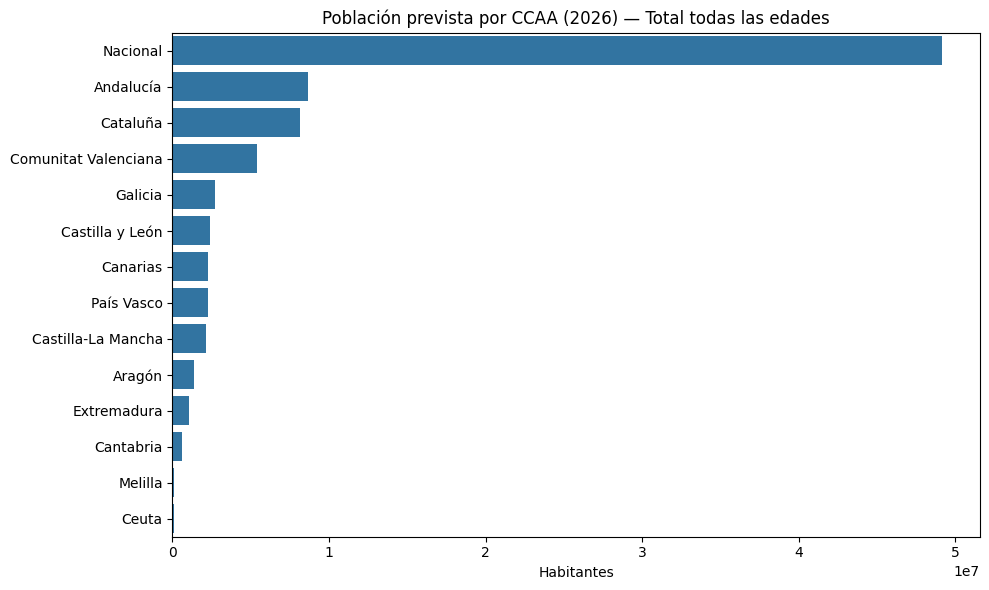

In [132]:
import matplotlib.pyplot as plt
import seaborn as sns

pretty = {
    "nacional":"Nacional", "andalucia":"Andalucía", "aragon":"Aragón",
    "asturias":"Asturias", "balears":"Illes Balears", "canarias":"Canarias",
    "cantabria":"Cantabria", "castilla_y_leon":"Castilla y León", "castilla_la_mancha":"Castilla-La Mancha",
    "cataluna":"Cataluña", "comunitat_valenciana":"Comunitat Valenciana", "extremadura":"Extremadura",
    "galicia":"Galicia", "madrid":"Madrid", "murcia":"Murcia", "navarra":"Navarra",
    "pais_vasco":"País Vasco", "rioja":"La Rioja", "ceuta":"Ceuta", "melilla":"Melilla",
}

df_total["ccaa_pretty"] = df_total["ccaa"].map(pretty).fillna(df_total["ccaa"])

df_plot = df_total.sort_values("pred_poblacion_2026", ascending=False)

plt.figure(figsize=(10,6))
sns.barplot(data=df_plot, y="ccaa_pretty", x="pred_poblacion_2026")
plt.title("Población prevista por CCAA (2026) — Total todas las edades")
plt.xlabel("Habitantes")
plt.ylabel("")
plt.tight_layout()
plt.show()

**2. Población por Nacionalidad y CCAA**

ANÁLISIS DE NACIONALIDADES POR CCAA

Total de filas encontradas: 280
Nacionalidades únicas: ['apatridas', 'de_africa', 'de_america_del_norte', 'de_asia', 'de_centro_america_y_caribe', 'de_oceania', 'de_sudamerica', 'espanola', 'extranjera', 'pais_de_europa_menos_ue27_2020', 'pais_de_europa_menos_ue28', 'pais_de_la_ue27_2020_sin_espana', 'pais_de_la_ue28_sin_espana', 'total']

✓ Datos de nacionalidades encontrados: 260 filas

RESUMEN POR COMUNIDAD AUTÓNOMA

ANDALUCÍA
--------------------------------------------------------------------------------
  Española                      :    7,788,736 (81.27%)
  Extranjera                    :      897,249 ( 9.36%)
  África                        :      236,597 ( 2.47%)
  UE27 (sin España)             :      233,240 ( 2.43%)
  Sudamérica                    :      180,435 ( 1.88%)
  Europa no UE27                :      145,429 ( 1.52%)
  Asia                          :       45,624 ( 0.48%)
  Centro América y Caribe       :       42,439 ( 0.44%)


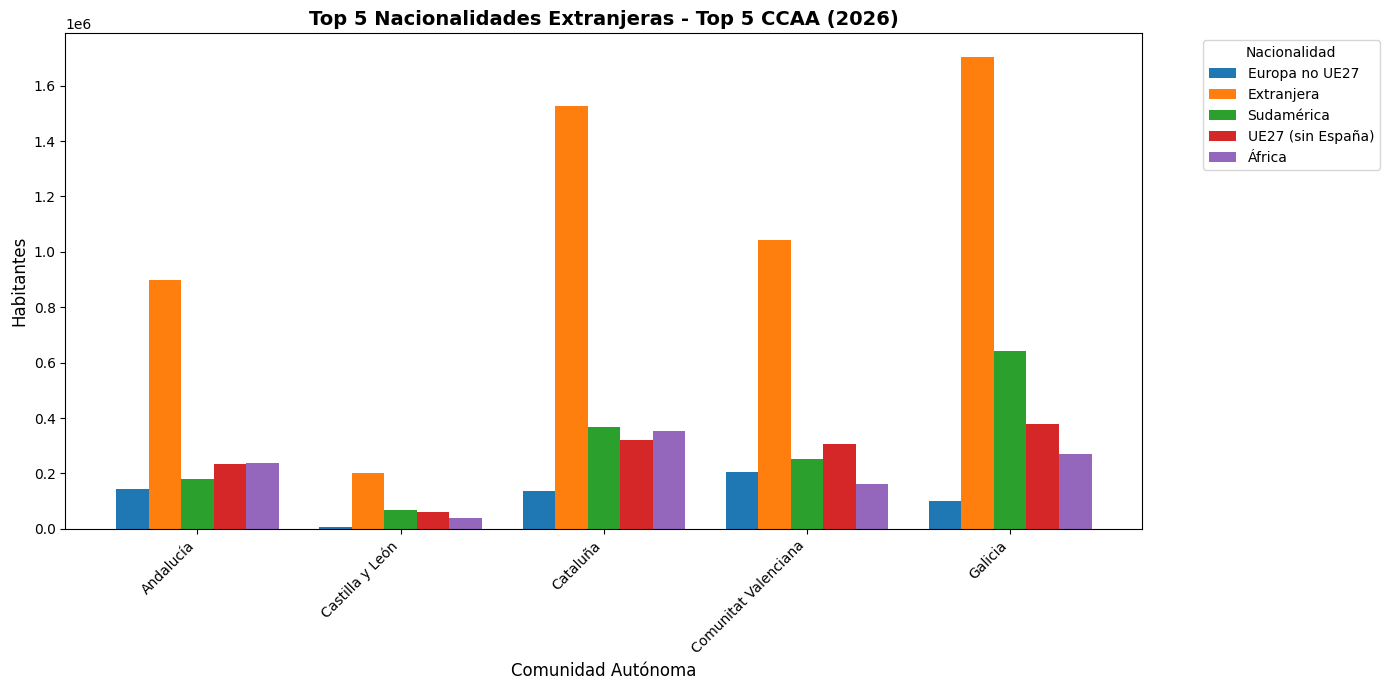


Tabla de datos:
nac_pretty            Europa no UE27  Extranjera  Sudamérica  UE27 (sin España)  África
ccaa_pretty                                                                            
Andalucía                     145429      897249      180435             233240  236597
Castilla y León                 8051      199785       68157              58917   37340
Cataluña                      137651     1527778      366181             322295  352397
Comunitat Valenciana          204410     1041921      252796             305916  160507
Galicia                        99575     1703857      641093             377009  270419


In [133]:
# ANÁLISIS DIRECTO POR NACIONALIDADES - Leyendo datos con predicciones
print("=" * 80)
print("ANÁLISIS DE NACIONALIDADES POR CCAA")
print("=" * 80)

# Filtrar datos: total sexo, todas las edades, con nacionalidades específicas
df_nac_data = df_pred_2026[
    df_pred_2026["key"].str.contains("total_todas_las_edades")
].copy()

print(f"\nTotal de filas encontradas: {len(df_nac_data)}")
print(f"Nacionalidades únicas: {sorted(df_nac_data['nacionalidad'].unique())}")

# Separar por total y específicas
df_con_nacionalidades = df_nac_data[df_nac_data['nacionalidad'] != 'total'].copy()

if len(df_con_nacionalidades) > 0:
    print(f"\n✓ Datos de nacionalidades encontrados: {len(df_con_nacionalidades)} filas")
    
    # Diccionario de nombres para nacionalidades 
    nac_nombres = {
        "total": "Total",
        "espanola": "Española",
        "pais_de_la_ue27_2020_sin_espana": "UE27 (sin España)",
        "pais_de_la_ue28_sin_espana": "UE28 (sin España)",
        "pais_de_europa_menos_ue27_2020": "Europa no UE27",
        "pais_de_europa_menos_ue28": "Europa no UE28",
        "de_africa": "África",
        "de_america_del_norte": "América del Norte",
        "de_centro_america_y_caribe": "Centro América y Caribe",
        "de_sudamerica": "Sudamérica",
        "de_asia": "Asia",
        "de_oceania": "Oceanía",
        "apatridas": "Apátridas",
        "extranjera": "Extranjera"
    }
    
    # Agregar por CCAA y nacionalidad
    nac_por_ccaa = df_con_nacionalidades.groupby(['ccaa', 'nacionalidad'])['pred_poblacion_2026'].sum().reset_index()
    nac_por_ccaa['ccaa_pretty'] = nac_por_ccaa['ccaa'].map(pretty).fillna(nac_por_ccaa['ccaa'])
    nac_por_ccaa['nac_pretty'] = nac_por_ccaa['nacionalidad'].map(nac_nombres).fillna(nac_por_ccaa['nacionalidad'])
    
    # Mostrar resumen por CCAA
    print("\n" + "=" * 80)
    print("RESUMEN POR COMUNIDAD AUTÓNOMA")
    print("=" * 80)
    
    for ccaa_code in sorted(nac_por_ccaa['ccaa'].unique()):
        ccaa_data = nac_por_ccaa[nac_por_ccaa['ccaa'] == ccaa_code].copy()
        ccaa_nombre = ccaa_data.iloc[0]['ccaa_pretty']
        total_ccaa = ccaa_data['pred_poblacion_2026'].sum()
        
        print(f"\n{ccaa_nombre.upper()}")
        print("-" * 80)
        
        # Ordenar por población
        ccaa_data_sorted = ccaa_data.sort_values('pred_poblacion_2026', ascending=False)
        
        for _, row in ccaa_data_sorted.iterrows():
            pob = row['pred_poblacion_2026']
            if pob > 0:
                pct = (pob / total_ccaa * 100) if total_ccaa > 0 else 0
                print(f"  {row['nac_pretty']:30s}: {pob:>12,.0f} ({pct:>5.2f}%)")
    
    # Visualización: Top 5 CCAA y top nacionalidades
    print("\n" + "=" * 80)
    print("GRÁFICO: TOP 5 CCAA - PRINCIPALES NACIONALIDADES")
    print("=" * 80)
    
    # Top 5 CCAA por población total
    top5_ccaa = df_total[df_total['ccaa'] != 'nacional'].nlargest(5, 'pred_poblacion_2026')['ccaa'].values
    
    # Top 5 nacionalidades (excluyendo española para ver mejor los extranjeros)
    top_nac_global = nac_por_ccaa[nac_por_ccaa['nacionalidad'] != 'espanola'].groupby('nacionalidad')['pred_poblacion_2026'].sum().nlargest(5).index.tolist()
    
    # Filtrar datos
    df_viz = nac_por_ccaa[
        (nac_por_ccaa['ccaa'].isin(top5_ccaa)) & 
        (nac_por_ccaa['nacionalidad'].isin(top_nac_global))
    ].copy()
    
    if len(df_viz) > 0:
        # Pivot para gráfico
        pivot_viz = df_viz.pivot(index='ccaa_pretty', columns='nac_pretty', values='pred_poblacion_2026').fillna(0)
        
        # Gráfico de barras
        ax = pivot_viz.plot(kind='bar', figsize=(14, 7), width=0.8)
        plt.title('Top 5 Nacionalidades Extranjeras - Top 5 CCAA (2026)', fontsize=14, fontweight='bold')
        plt.xlabel('Comunidad Autónoma', fontsize=12)
        plt.ylabel('Habitantes', fontsize=12)
        plt.legend(title='Nacionalidad', bbox_to_anchor=(1.05, 1), loc='upper left')
        plt.xticks(rotation=45, ha='right')
        plt.tight_layout()
        plt.show()
        
        # Mostrar tabla
        print("\nTabla de datos:")
        print(pivot_viz.to_string())
    
else:
    print("\n⚠️ No se encontraron datos desglosados por nacionalidad en las predicciones.")
    print("Mostrando análisis alternativo...")
    
    # Análisis alternativo
    df_ccaa_only = df_total[df_total['ccaa'] != 'nacional'].copy()
    df_ccaa_only = df_ccaa_only.sort_values('pred_poblacion_2026', ascending=True).tail(10)
    
    plt.figure(figsize=(12, 6))
    plt.barh(df_ccaa_only['ccaa_pretty'], df_ccaa_only['pred_poblacion_2026'], color='steelblue', alpha=0.8)
    plt.title('Top 10 CCAA por Población Total Prevista (2026)')
    plt.xlabel('Habitantes')
    plt.ylabel('')
    plt.tight_layout()
    plt.show()

3. Análisis Detallado por Nacionalidad

In [134]:
# Análisis completo de población por nacionalidad (nivel nacional)
# Filtrar solo datos de total sexo, todas las edades, nivel nacional

df_nac_nacional = df_pred_2026[
    (df_pred_2026["key"].str.contains("total_todas_las_edades_")) & 
    (df_pred_2026["ccaa"] == "nacional")
].copy()

print("=" * 80)
print("POBLACIÓN PREVISTA 2026 POR NACIONALIDAD - NIVEL NACIONAL")
print("=" * 80)

# Diccionario para nombres bonitos de nacionalidades
nac_pretty = {
    "total": "TOTAL NACIONAL",
    "espanola": "Española",
    "pais_de_la_ue27_2020_sin_espana": "UE27 (sin España)",
    "pais_de_la_ue28_sin_espana": "UE28 (sin España)",
    "pais_de_europa_menos_ue27_2020": "Europa no UE27",
    "pais_de_europa_menos_ue28": "Europa no UE28",
    "de_africa": "África",
    "de_america_del_norte": "América del Norte",
    "de_centro_america_y_caribe": "Centro América y Caribe",
    "de_sudamerica": "Sudamérica",
    "de_asia": "Asia",
    "de_oceania": "Oceanía",
    "apatridas": "Apátridas",
    "extranjera": "Extranjera"
}

df_nac_nacional['nac_pretty'] = df_nac_nacional['nacionalidad'].map(nac_pretty).fillna(df_nac_nacional['nacionalidad'])

# Ordenar por población
df_nac_nacional_sorted = df_nac_nacional.sort_values('pred_poblacion_2026', ascending=False)

# Mostrar tabla
for i, (_, row) in enumerate(df_nac_nacional_sorted.iterrows(), 1):
    pob = row['pred_poblacion_2026']
    if pob > 0:  # Solo mostrar nacionalidades con población
        print(f"{i:2d}. {row['nac_pretty']:30s}: {pob:>12,.0f} habitantes")

print("=" * 80)

# Calcular porcentajes (excluyendo total)
df_nac_sin_total = df_nac_nacional[df_nac_nacional['nacionalidad'] != 'total'].copy()
total_pob = df_nac_nacional[df_nac_nacional['nacionalidad'] == 'total']['pred_poblacion_2026'].values[0]

if total_pob > 0:
    print("\nPORCENTAJE SOBRE POBLACIÓN TOTAL:")
    print("-" * 80)
    df_nac_sin_total = df_nac_sin_total.sort_values('pred_poblacion_2026', ascending=False)
    for _, row in df_nac_sin_total.iterrows():
        if row['pred_poblacion_2026'] > 0:
            pct = (row['pred_poblacion_2026'] / total_pob * 100)
            print(f"{row['nac_pretty']:30s}: {pct:>6.2f}%")
    print("=" * 80)

POBLACIÓN PREVISTA 2026 POR NACIONALIDAD - NIVEL NACIONAL
 1. TOTAL NACIONAL                :   49,121,007 habitantes
 2. Española                      :   42,223,381 habitantes
 3. Extranjera                    :    6,897,639 habitantes
 4. Sudamérica                    :    1,930,277 habitantes
 5. UE27 (sin España)             :    1,773,684 habitantes
 6. África                        :    1,354,446 habitantes
 7. Europa no UE27                :      710,954 habitantes
 8. Asia                          :      554,241 habitantes
 9. Centro América y Caribe       :      464,602 habitantes
10. América del Norte             :      102,006 habitantes
11. Oceanía                       :        4,934 habitantes
12. Apátridas                     :        4,701 habitantes

PORCENTAJE SOBRE POBLACIÓN TOTAL:
--------------------------------------------------------------------------------
Española                      :  85.96%
Extranjera                    :  14.04%
Sudamérica                

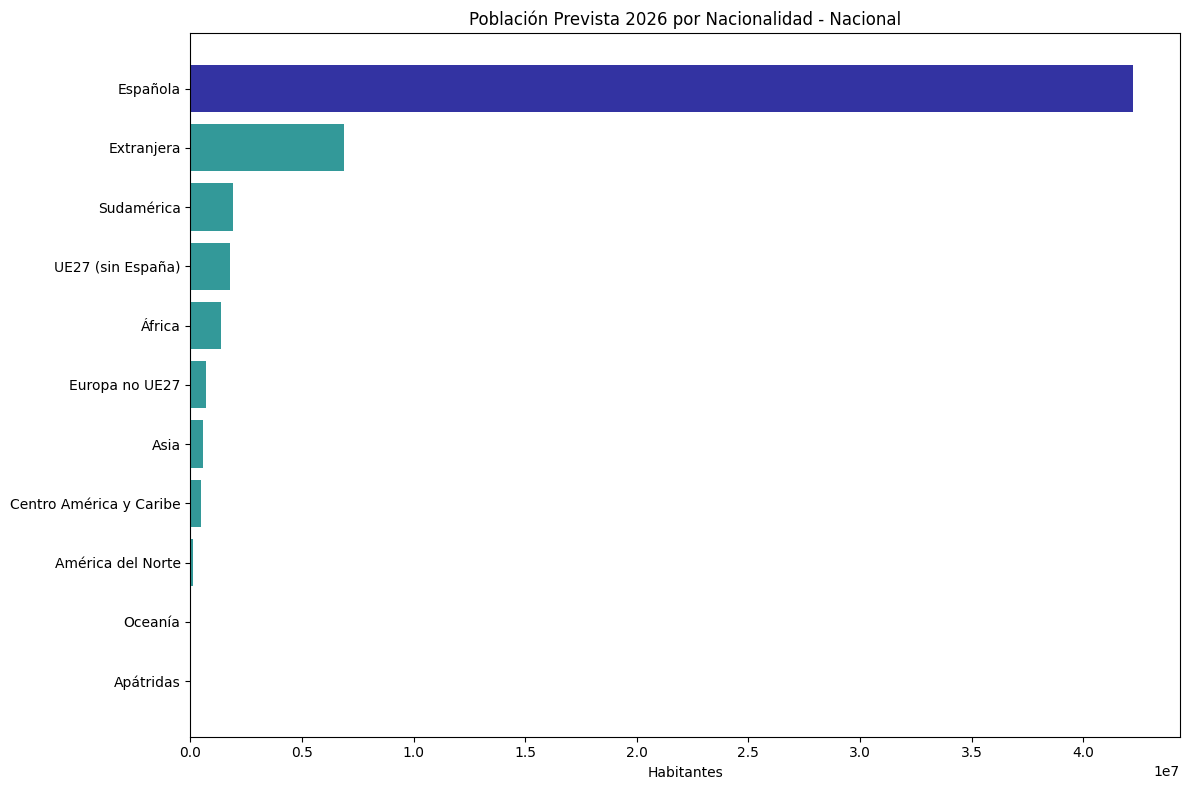

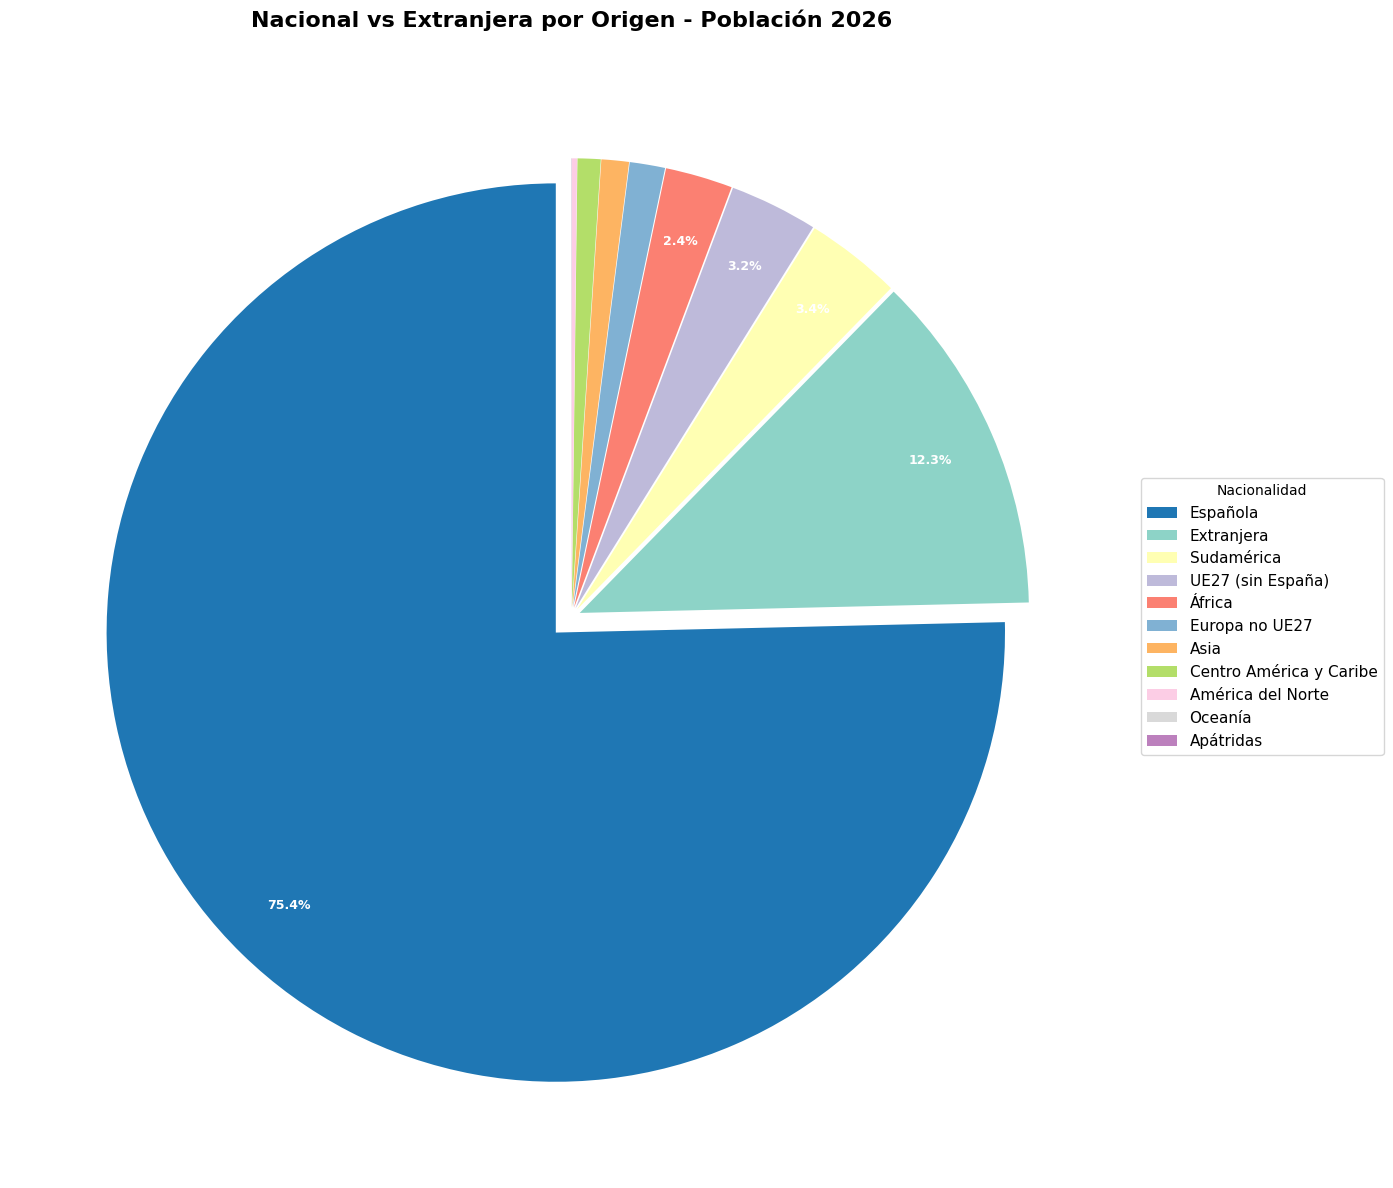


RESUMEN POBLACIÓN NACIONAL VS EXTRANJERA POR ORIGEN
Nacionalidad                        Habitantes        %
--------------------------------------------------------------------------------
Española                            42,223,381   85.96%
--------------------------------------------------------------------------------
Extranjera                           6,897,639   14.04%
Sudamérica                           1,930,277    3.93%
UE27 (sin España)                    1,773,684    3.61%
África                               1,354,446    2.76%
Europa no UE27                         710,954    1.45%
Asia                                   554,241    1.13%
Centro América y Caribe                464,602    0.95%
América del Norte                      102,006    0.21%
Oceanía                                  4,934    0.01%
Apátridas                                4,701    0.01%
--------------------------------------------------------------------------------
SUBTOTAL EXTRANJERA             

In [135]:
# Visualización 1: Gráfico de barras INCLUYENDO Española (todas las nacionalidades)
df_viz_completo = df_nac_sin_total[
    (df_nac_sin_total['pred_poblacion_2026'] > 0)
].copy()

if len(df_viz_completo) > 0:
    df_viz_completo = df_viz_completo.sort_values('pred_poblacion_2026', ascending=True)
    
    plt.figure(figsize=(12, 8))
    # Color diferente para española vs extranjeros
    colors = ['darkblue' if nac == 'espanola' else 'teal' for nac in df_viz_completo['nacionalidad']]
    plt.barh(df_viz_completo['nac_pretty'], df_viz_completo['pred_poblacion_2026'], color=colors, alpha=0.8)
    plt.xlabel('Habitantes')
    plt.ylabel('')
    plt.title('Población Prevista 2026 por Nacionalidad - Nacional')
    plt.tight_layout()
    plt.show()
    
    # Visualización 2: Gráfico de pastel Nacional vs Extranjera por Origen
    # Preparar datos: Española + cada origen extranjero
    pob_espanola = df_nac_sin_total[df_nac_sin_total['nacionalidad'] == 'espanola']['pred_poblacion_2026'].sum()
    
    # Obtener poblaciones extranjeras por origen (excluyendo española y solo valores positivos)
    df_extranjeros = df_nac_sin_total[
        (df_nac_sin_total['nacionalidad'] != 'espanola') &
        (df_nac_sin_total['pred_poblacion_2026'] > 0)
    ].copy()
    df_extranjeros = df_extranjeros.sort_values('pred_poblacion_2026', ascending=False)
    
    if len(df_extranjeros) > 0 and pob_espanola > 0:
        # Crear listas para el pie chart
        categorias = ['Española'] + df_extranjeros['nac_pretty'].tolist()
        valores = [pob_espanola] + df_extranjeros['pred_poblacion_2026'].tolist()
        
        # Paleta de colores: azul para española, otros colores para extranjeros
        import matplotlib.cm as cm
        colores = ['#1f77b4']  # Azul para española
        colores_extranjeros = cm.Set3(range(len(df_extranjeros)))
        colores.extend(colores_extranjeros)
        
        # Crear explode para separar ligeramente las porciones pequeñas
        explode = [0.05 if i == 0 else 0.02 for i in range(len(valores))]
        
        fig, ax = plt.subplots(figsize=(14, 14))
        
        wedges, texts, autotexts = ax.pie(
            valores, 
            labels=None,  # No mostrar etiquetas en el gráfico
            autopct=lambda pct: f'{pct:.1f}%' if pct > 2 else '',  # Solo mostrar % si es > 2%
            startangle=90,
            colors=colores,
            explode=explode,
            pctdistance=0.85,
            textprops={'fontsize': 9}
        )
        
        for autotext in autotexts:
            autotext.set_color('white')
            autotext.set_fontsize(9)
            autotext.set_weight('bold')
        
        # Crear leyenda fuera del gráfico
        ax.legend(
            wedges, 
            categorias,
            title="Nacionalidad",
            loc="center left",
            bbox_to_anchor=(1, 0, 0.5, 1),
            fontsize=11
        )
        
        plt.title('Nacional vs Extranjera por Origen - Población 2026', 
                  fontsize=16, fontweight='bold', pad=20)
        plt.tight_layout()
        plt.show()
        
        # Mostrar tabla resumen
        print("\n" + "=" * 80)
        print("RESUMEN POBLACIÓN NACIONAL VS EXTRANJERA POR ORIGEN")
        print("=" * 80)
        print(f"{'Nacionalidad':30s} {'Habitantes':>15s} {'%':>8s}")
        print("-" * 80)
        print(f"{'Española':30s} {pob_espanola:>15,.0f} {pob_espanola/total_pob*100:>7.2f}%")
        print("-" * 80)
        for _, row in df_extranjeros.iterrows():
            pob = row['pred_poblacion_2026']
            print(f"{row['nac_pretty']:30s} {pob:>15,.0f} {pob/total_pob*100:>7.2f}%")
        print("-" * 80)
        pob_extranjera_total = df_extranjeros['pred_poblacion_2026'].sum()
        print(f"{'SUBTOTAL EXTRANJERA':30s} {pob_extranjera_total:>15,.0f} {pob_extranjera_total/total_pob*100:>7.2f}%")
        print("=" * 80)
        print(f"{'TOTAL':30s} {total_pob:>15,.0f} {'100.00':>7s}%")
        print("=" * 80)
    else:
        print("\n⚠️ No hay suficientes datos válidos para el gráfico de pastel")
else:
    print("No hay datos de nacionalidades disponibles")

**4.Comparativa de nacionalidades por CCAA (Top 5 nacionalidades extranjeras)**

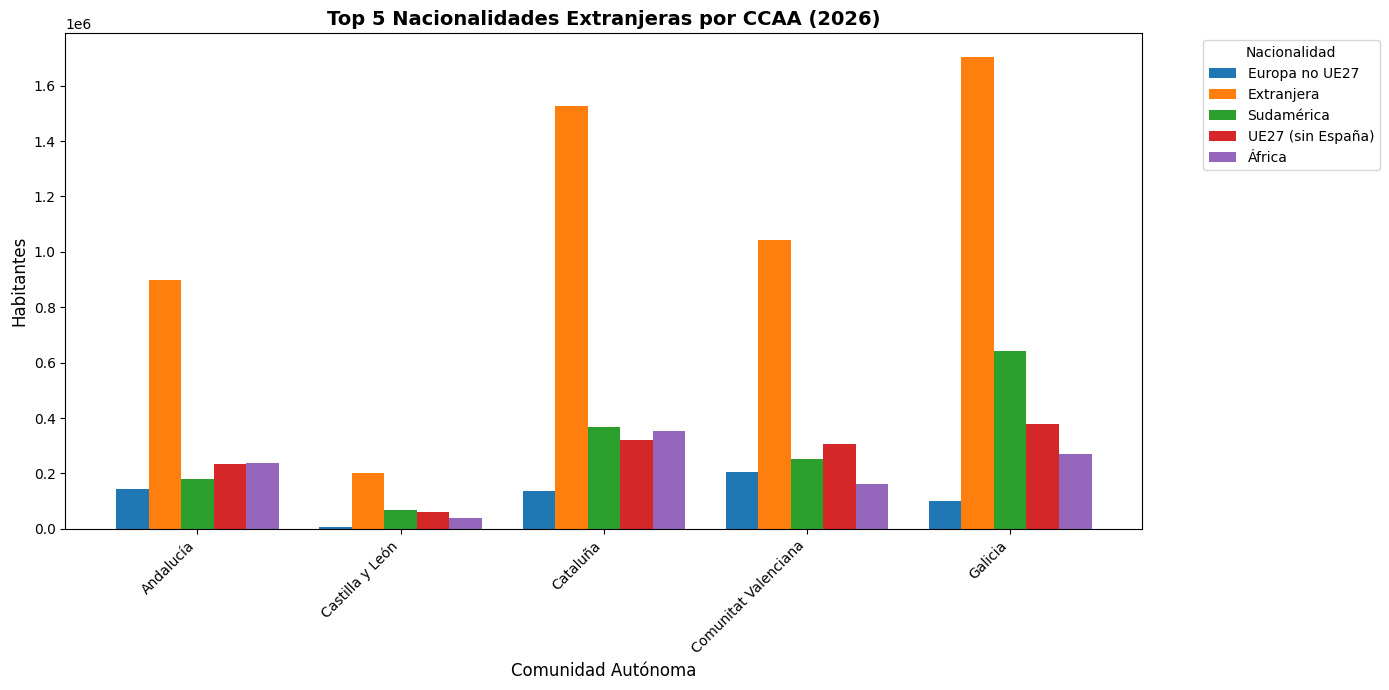


RESUMEN: TOP 5 NACIONALIDADES POR CCAA
nac_pretty            Europa no UE27  Extranjera  Sudamérica  UE27 (sin España)  África
ccaa_pretty                                                                            
Andalucía                     145429      897249      180435             233240  236597
Castilla y León                 8051      199785       68157              58917   37340
Cataluña                      137651     1527778      366181             322295  352397
Comunitat Valenciana          204410     1041921      252796             305916  160507
Galicia                        99575     1703857      641093             377009  270419


In [136]:

df_nac_por_ccaa = df_pred_2026[
    (df_pred_2026["key"].str.startswith("total_todas_las_edades_")) &  # Solo sexo total
    (~df_pred_2026["nacionalidad"].isin(['total', 'espanola'])) &
    (df_pred_2026["ccaa"] != "nacional") &
    (df_pred_2026['pred_poblacion_2026'] > 0)
].copy()

if len(df_nac_por_ccaa) > 0:
    # Top 5 nacionalidades a nivel nacional
    top_nac = df_nac_sin_total[~df_nac_sin_total['nacionalidad'].isin(['total', 'espanola'])].nlargest(5, 'pred_poblacion_2026')['nacionalidad'].values
    
    # Filtrar por esas nacionalidades
    df_nac_top = df_nac_por_ccaa[df_nac_por_ccaa['nacionalidad'].isin(top_nac)].copy()
    
    # Top 5 CCAA por población
    top5_ccaa = df_total[df_total['ccaa'] != 'nacional'].nlargest(5, 'pred_poblacion_2026')['ccaa'].values
    
    df_nac_top_ccaa = df_nac_top[df_nac_top['ccaa'].isin(top5_ccaa)].copy()
    df_nac_top_ccaa['nac_pretty'] = df_nac_top_ccaa['nacionalidad'].map(nac_pretty)
    df_nac_top_ccaa['ccaa_pretty'] = df_nac_top_ccaa['ccaa'].map(pretty)
    
    # Agrupar para evitar duplicados (sumar si hay múltiples entradas)
    df_nac_grouped = df_nac_top_ccaa.groupby(['ccaa_pretty', 'nac_pretty'])['pred_poblacion_2026'].sum().reset_index()
    
    # Pivot para visualización (ahora sin duplicados)
    pivot_final = df_nac_grouped.pivot(index='ccaa_pretty', columns='nac_pretty', values='pred_poblacion_2026').fillna(0)
    
    if not pivot_final.empty:
        # Gráfico de barras agrupadas
        ax = pivot_final.plot(kind='bar', figsize=(14, 7), width=0.8)
        plt.title('Top 5 Nacionalidades Extranjeras por CCAA (2026)', fontsize=14, fontweight='bold')
        plt.xlabel('Comunidad Autónoma', fontsize=12)
        plt.ylabel('Habitantes', fontsize=12)
        plt.legend(title='Nacionalidad', bbox_to_anchor=(1.05, 1), loc='upper left')
        plt.xticks(rotation=45, ha='right')
        plt.tight_layout()
        plt.show()
        
        # Tabla resumen
        print("\n" + "=" * 100)
        print("RESUMEN: TOP 5 NACIONALIDADES POR CCAA")
        print("=" * 100)
        print(pivot_final.to_string())
        print("=" * 100)
else:
    print("No hay suficientes datos de nacionalidades por CCAA")

**5. Ratio Hombres/Mujeres por CCAA**

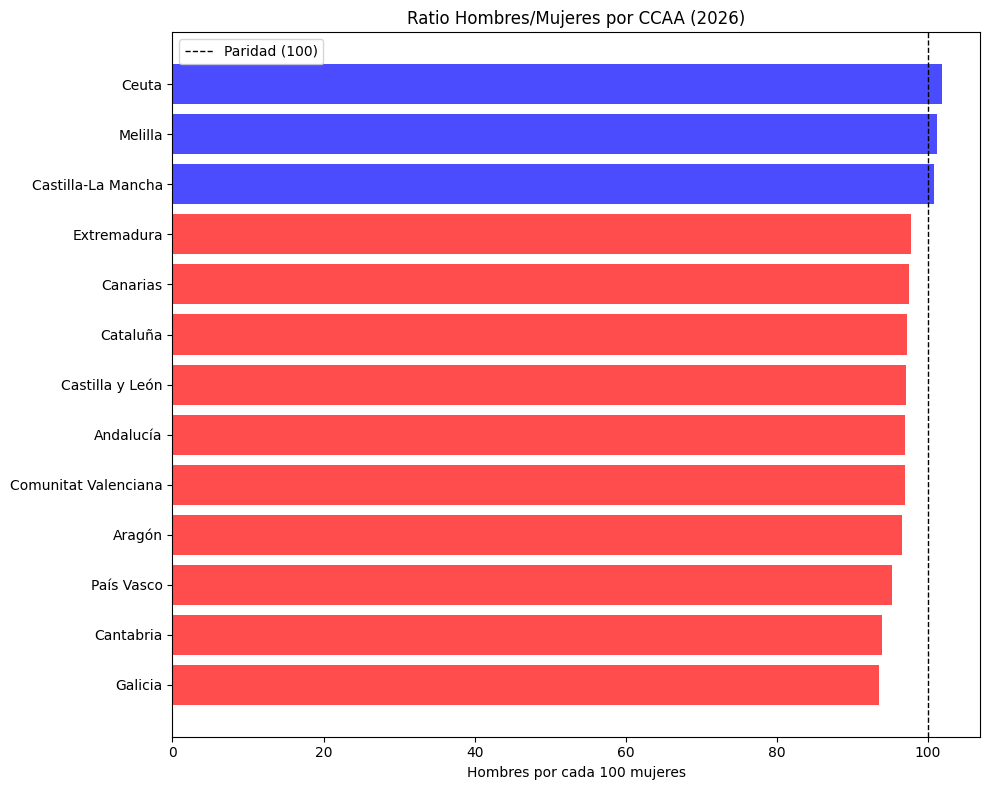


Ratio Hombres/Mujeres por CCAA:
Galicia                  :  93.54 hombres por cada 100 mujeres
Cantabria                :  93.94 hombres por cada 100 mujeres
País Vasco               :  95.18 hombres por cada 100 mujeres
Nacional                 :  96.20 hombres por cada 100 mujeres
Aragón                   :  96.60 hombres por cada 100 mujeres
Comunitat Valenciana     :  96.90 hombres por cada 100 mujeres
Andalucía                :  96.92 hombres por cada 100 mujeres
Castilla y León          :  97.07 hombres por cada 100 mujeres
Cataluña                 :  97.24 hombres por cada 100 mujeres
Canarias                 :  97.45 hombres por cada 100 mujeres
Extremadura              :  97.73 hombres por cada 100 mujeres
Castilla-La Mancha       : 100.79 hombres por cada 100 mujeres
Melilla                  : 101.16 hombres por cada 100 mujeres
Ceuta                    : 101.78 hombres por cada 100 mujeres


In [137]:
# Filtrar hombres y mujeres (todas edades, nacionalidad total)
# CORRECCIÓN: Asegurar que solo capturamos una fila por CCAA
df_hombres = df_pred_2026[
    (df_pred_2026["key"].str.startswith("hombres_todas_las_edades_total_")) &
    (df_pred_2026["nacionalidad"] == "total")
].copy()

df_mujeres = df_pred_2026[
    (df_pred_2026["key"].str.startswith("mujeres_todas_las_edades_total_")) &
    (df_pred_2026["nacionalidad"] == "total")
].copy()

# Agrupar por CCAA para eliminar duplicados
df_hombres = df_hombres.groupby('ccaa', as_index=False)['pred_poblacion_2026'].sum()
df_mujeres = df_mujeres.groupby('ccaa', as_index=False)['pred_poblacion_2026'].sum()

# Crear DataFrame con ratio
df_ratio = pd.DataFrame({
    'ccaa': df_hombres['ccaa'].values,
    'hombres': df_hombres['pred_poblacion_2026'].values,
    'mujeres': df_mujeres['pred_poblacion_2026'].values
})

df_ratio['ratio'] = (df_ratio['hombres'] / df_ratio['mujeres'] * 100).round(2)
df_ratio['ccaa_pretty'] = df_ratio['ccaa'].map(pretty).fillna(df_ratio['ccaa'])

# Excluir Nacional para mejor visualización
df_ratio_plot = df_ratio[df_ratio['ccaa'] != 'nacional'].sort_values('ratio')

plt.figure(figsize=(10, 8))
colors = ['red' if r < 100 else 'blue' for r in df_ratio_plot['ratio']]
plt.barh(df_ratio_plot['ccaa_pretty'], df_ratio_plot['ratio'], color=colors, alpha=0.7)
plt.axvline(100, color='black', linestyle='--', linewidth=1, label='Paridad (100)')
plt.xlabel('Hombres por cada 100 mujeres')
plt.ylabel('')
plt.title('Ratio Hombres/Mujeres por CCAA (2026)')
plt.legend()
plt.tight_layout()
plt.show()

print("\nRatio Hombres/Mujeres por CCAA:")
for _, row in df_ratio.sort_values('ratio').iterrows():
    print(f"{row['ccaa_pretty']:25s}: {row['ratio']:>6.2f} hombres por cada 100 mujeres")

**6. Distribución por Grupos de Edad - Top CCAA**

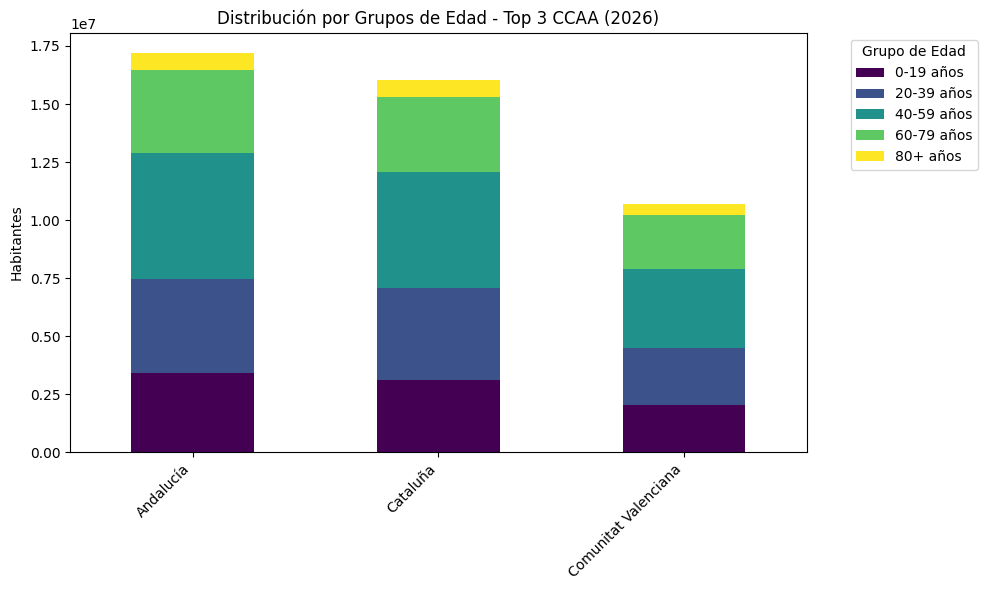

In [138]:
# Extraer grupo de edad de la clave
def extract_edad_from_key(k: str) -> str:
    k = str(k)
    if "todas_las_edades" in k:
        return "Todas las edades"
    # Buscar patrones de edad
    if "de_0_a" in k or "de_5_a" in k or "de_10_a" in k or "de_15_a" in k:
        if "de_0_a" in k or "de_5_a" in k or "de_10_a" in k or "de_15_a_19" in k:
            return "0-19 años"
    if "de_20_a" in k or "de_25_a" in k or "de_30_a" in k or "de_35_a" in k:
        return "20-39 años"
    if "de_40_a" in k or "de_45_a" in k or "de_50_a" in k or "de_55_a" in k:
        return "40-59 años"
    if "de_60_a" in k or "de_65_a" in k or "de_70_a" in k or "de_75_a" in k:
        return "60-79 años"
    if "80_y_mas" in k or "de_80_a" in k or "de_85_a" in k or "de_90_a" in k or "de_95_a" in k or "100_y_mas" in k:
        return "80+ años"
    return "Otras edades"

# Aplicar extracción
df_pred_2026['grupo_edad'] = df_pred_2026['key'].apply(extract_edad_from_key)

# Filtrar datos (total sexo, total nacionalidad)
df_edad = df_pred_2026[
    df_pred_2026["key"].str.contains("total_") & 
    df_pred_2026["key"].str.contains("_total_") &
    ~df_pred_2026["key"].str.contains("todas_las_edades")
].copy()

# Top 3 CCAA (excluyendo Nacional)
top3_ccaa = df_total[df_total['ccaa'] != 'nacional'].nlargest(3, 'pred_poblacion_2026')['ccaa'].values

# ✅ CORRECCIÓN: Eliminar duplicados antes de agregar
df_edad_sin_dup = df_edad.drop_duplicates(subset=['ccaa', 'key'], keep='first')
edad_summary = df_edad_sin_dup[df_edad_sin_dup['ccaa'].isin(top3_ccaa)].groupby(['ccaa', 'grupo_edad'])['pred_poblacion_2026'].sum().reset_index()
edad_summary['ccaa_pretty'] = edad_summary['ccaa'].map(pretty).fillna(edad_summary['ccaa'])

# Pivot
pivot_edad = edad_summary.pivot(index='ccaa_pretty', columns='grupo_edad', values='pred_poblacion_2026').fillna(0)

# Ordenar columnas de edad
edad_order = ['0-19 años', '20-39 años', '40-59 años', '60-79 años', '80+ años']
cols_edad = [c for c in edad_order if c in pivot_edad.columns]
pivot_edad = pivot_edad[cols_edad]

# Visualización
pivot_edad.plot(kind='bar', stacked=True, figsize=(10, 6), colormap='viridis')
plt.title('Distribución por Grupos de Edad - Top 3 CCAA (2026)')
plt.xlabel('')
plt.ylabel('Habitantes')
plt.legend(title='Grupo de Edad', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

**7. Dashboard Resumen por CCAA**

In [139]:
# Crear tabla resumen consolidada
dashboard = df_total[df_total['ccaa'] != 'nacional'].copy()
dashboard = dashboard.merge(
    df_ratio[['ccaa', 'ratio', 'hombres', 'mujeres']], 
    on='ccaa', 
    how='left'
)

# Seleccionar y renombrar columnas (sin datos de extranjeros ya que no están disponibles)
dashboard_final = dashboard[[
    'ccaa_pretty', 
    'pred_poblacion_2026', 
    'hombres', 
    'mujeres',
    'ratio'
]].copy()

dashboard_final.columns = [
    'CCAA',
    'Población Total',
    'Hombres',
    'Mujeres',
    'Ratio H/M'
]

dashboard_final = dashboard_final.sort_values('Población Total', ascending=False)

print("=" * 100)
print("DASHBOARD RESUMEN - POBLACIÓN PREVISTA 2026 POR CCAA")
print("=" * 100)
print(dashboard_final.to_string(index=False))
print("=" * 100)

# Calcular algunos estadísticos adicionales
print("\n" + "=" * 100)
print("ESTADÍSTICAS ADICIONALES")
print("=" * 100)
print(f"Población total nacional prevista: {df_total[df_total['ccaa']=='nacional']['pred_poblacion_2026'].values[0]:>15,.0f} habitantes")
print(f"Población media por CCAA:          {dashboard_final['Población Total'].mean():>15,.0f} habitantes")
print(f"CCAA más poblada:                  {dashboard_final.iloc[0]['CCAA']:>15s} ({dashboard_final.iloc[0]['Población Total']:,.0f} hab.)")
print(f"CCAA menos poblada:                {dashboard_final.iloc[-1]['CCAA']:>15s} ({dashboard_final.iloc[-1]['Población Total']:,.0f} hab.)")
print(f"Ratio H/M nacional:                {df_ratio[df_ratio['ccaa']=='nacional']['ratio'].values[0]:>15.2f}")
print("=" * 100)

DASHBOARD RESUMEN - POBLACIÓN PREVISTA 2026 POR CCAA
                CCAA  Población Total  Hombres  Mujeres  Ratio H/M
           Andalucía          8685972  4275017  4410968      96.92
            Cataluña          8121600  4004046  4117568      97.24
Comunitat Valenciana          5410115  2662408  2747719      96.90
             Galicia          2716767  5846822  6250476      93.54
     Castilla y León          2402119  1183204  1218928      97.07
            Canarias          2260300  1115560  1144753      97.45
          País Vasco          2242074  1252945  1316440      95.18
  Castilla-La Mancha          2126984  1067666  1059332     100.79
              Aragón          1364527  1782761  1845504      96.60
         Extremadura          1054949   521414   533548      97.73
           Cantabria           594427   287932   306508      93.94
             Melilla            86549    43531    43032     101.16
               Ceuta            83403    42076    41340     101.78

ESTADÍST

**8. Evolución Temporal de la Población por CCAA**

In [140]:
# Preparar datos de evolución temporal
# Necesitamos reconstruir los datos históricos + predicción 2026

# Filtrar datos de total (sexo total, edad total, nacionalidad total) por CCAA
df_evol_keys = df_pred_2026[
    (df_pred_2026["key"].str.startswith("total_todas_las_edades_total_")) &
    (df_pred_2026["nacionalidad"] == "total")
].copy()

# ✅ CORRECCIÓN: Eliminar duplicados en lugar de sumar
df_evol = df_evol_keys.drop_duplicates(subset=['ccaa'], keep='first')

# Obtener índices de estas claves en el DataFrame original para extraer datos históricos
indices_historicos = []
for key in df_evol['key']:
    idx = headers_column[headers_column == key].index
    if len(idx) > 0:
        indices_historicos.append(idx[0])

# Crear DataFrame con datos históricos
df_historico = numeric_df.loc[indices_historicos].copy()
df_historico['ccaa'] = df_evol['ccaa'].values

# Añadir predicción 2026
df_historico[2026] = df_evol['pred_poblacion_2026'].values

# Agregar por CCAA (por si hay duplicados)
ccaa_list = df_historico['ccaa'].values
df_historico = df_historico.drop('ccaa', axis=1)
df_historico_agg = df_historico.groupby(ccaa_list).sum()

print("✓ Datos de evolución temporal preparados")
print(f"Años disponibles: {df_historico_agg.columns.min()} - {df_historico_agg.columns.max()}")
print(f"CCAA en análisis: {len(df_historico_agg)}")


✓ Datos de evolución temporal preparados
Años disponibles: 2002 - 2026
CCAA en análisis: 14


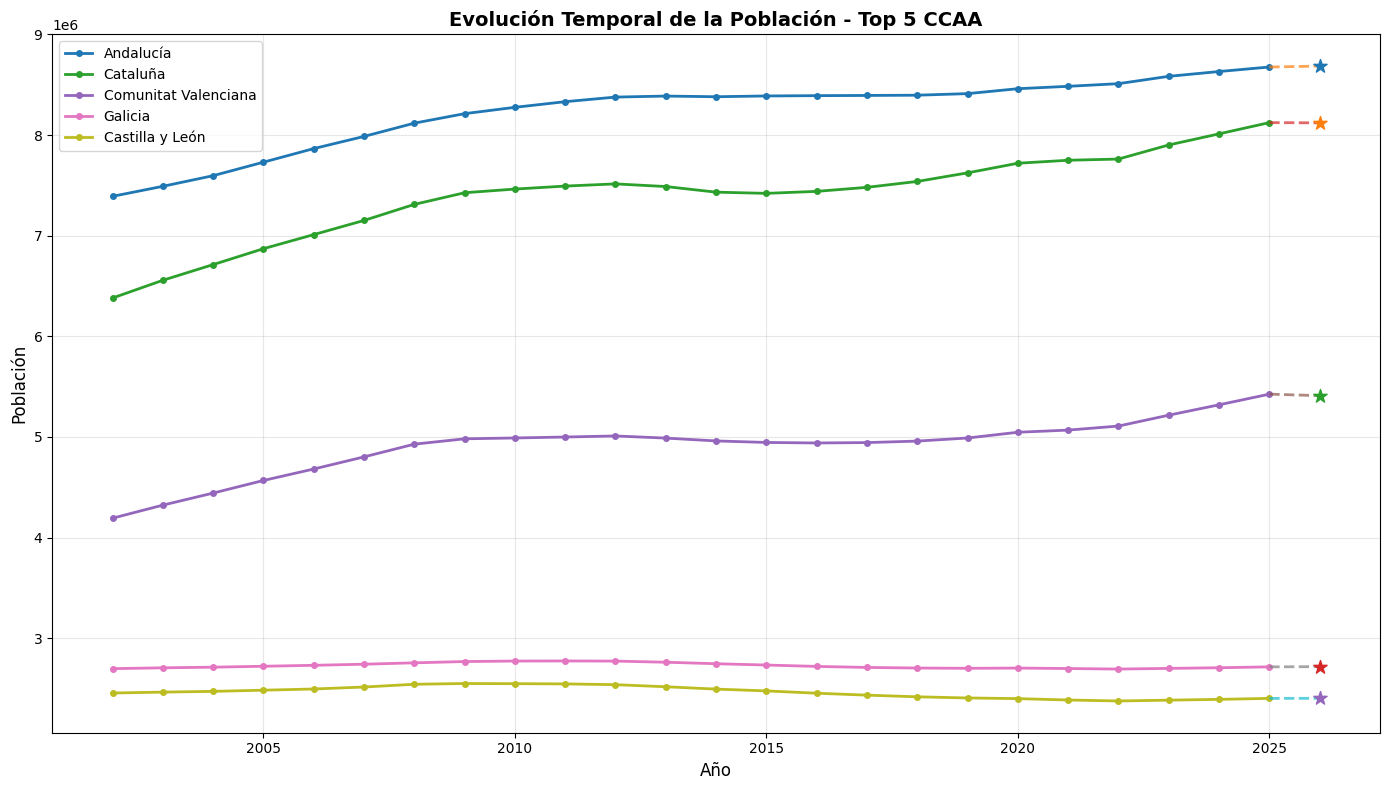

In [141]:
# Gráfico 1: Evolución de Top 5 CCAA más pobladas
top5_ccaa_evol = df_total[df_total['ccaa'] != 'nacional'].nlargest(5, 'pred_poblacion_2026')['ccaa'].values

plt.figure(figsize=(14, 8))

for ccaa in top5_ccaa_evol:
    if ccaa in df_historico_agg.index:
        valores = df_historico_agg.loc[ccaa]
        # Separar histórico de predicción
        years = valores.index
        historico_mask = years < 2026
        
        # Línea histórica
        plt.plot(years[historico_mask], valores[historico_mask], 
                marker='o', label=pretty.get(ccaa, ccaa), linewidth=2, markersize=4)
        
        # Línea de predicción (del último año histórico a 2026)
        if 2025 in years:
            plt.plot([2025, 2026], [valores[2025], valores[2026]], 
                    linestyle='--', linewidth=2, alpha=0.7)
            # Marcar el punto de predicción
            plt.scatter([2026], [valores[2026]], s=100, marker='*', zorder=5)

plt.xlabel('Año', fontsize=12)
plt.ylabel('Población', fontsize=12)
plt.title('Evolución Temporal de la Población - Top 5 CCAA', fontsize=14, fontweight='bold')
plt.legend(loc='best', fontsize=10)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


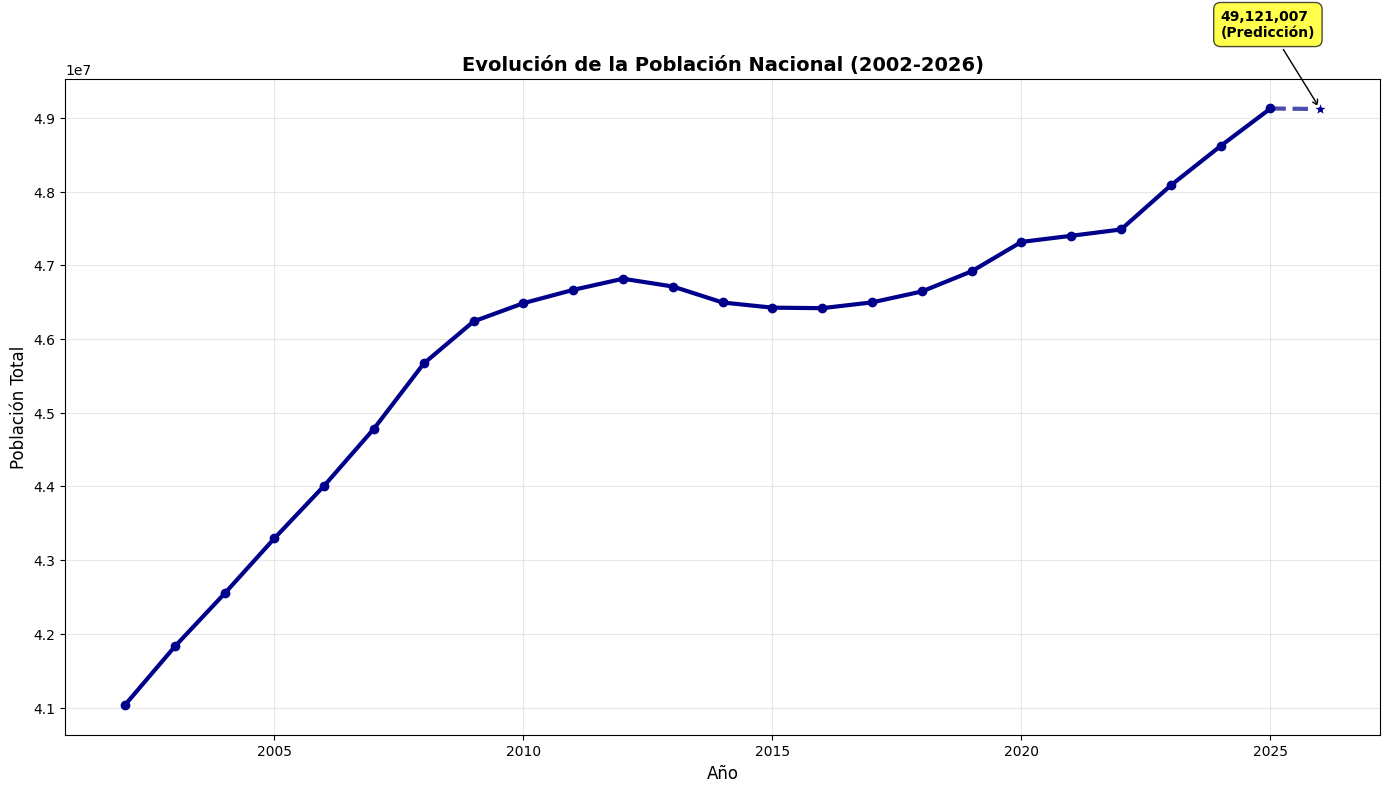

In [142]:
# Gráfico 2: Evolución Nacional vs suma de CCAA
nacional_data = df_historico_agg.loc['nacional'] if 'nacional' in df_historico_agg.index else None

if nacional_data is not None:
    plt.figure(figsize=(14, 8))
    
    years = nacional_data.index
    historico_mask = years < 2026
    
    # Línea histórica
    plt.plot(years[historico_mask], nacional_data[historico_mask], 
            marker='o', label='Nacional', linewidth=3, markersize=6, color='darkblue')
    
    # Línea de predicción
    if 2025 in years:
        plt.plot([2025, 2026], [nacional_data[2025], nacional_data[2026]], 
                linestyle='--', linewidth=3, alpha=0.7, color='darkblue')
        plt.scatter([2026], [nacional_data[2026]], s=200, marker='*', 
                   color='darkblue', zorder=5, edgecolor='white', linewidth=2)
    
    plt.xlabel('Año', fontsize=12)
    plt.ylabel('Población Total', fontsize=12)
    plt.title('Evolución de la Población Nacional (2002-2026)', fontsize=14, fontweight='bold')
    plt.grid(True, alpha=0.3)
    
    # Añadir anotación en 2026
    if 2026 in nacional_data.index:
        plt.annotate(f'{nacional_data[2026]:,.0f}\n(Predicción)', 
                    xy=(2026, nacional_data[2026]),
                    xytext=(2024, nacional_data[2026] * 1.02),
                    fontsize=10, fontweight='bold',
                    bbox=dict(boxstyle='round,pad=0.5', facecolor='yellow', alpha=0.7),
                    arrowprops=dict(arrowstyle='->', connectionstyle='arc3,rad=0'))
    
    plt.tight_layout()
    plt.show()


In [143]:
# Tabla: Tasas de crecimiento por CCAA
print("=" * 100)
print("TASAS DE CRECIMIENTO POBLACIONAL POR CCAA")
print("=" * 100)

# Calcular tasas de crecimiento
tasas_crecimiento = []

for ccaa in df_historico_agg.index:
    if ccaa != 'nacional':
        data = df_historico_agg.loc[ccaa]
        
        # Crecimiento 2002-2025 (histórico)
        if 2002 in data.index and 2025 in data.index:
            pob_2002 = data[2002]
            pob_2025 = data[2025]
            if pob_2002 > 0:
                crecimiento_total = ((pob_2025 - pob_2002) / pob_2002 * 100)
                crecimiento_anual = ((pob_2025 / pob_2002) ** (1/23) - 1) * 100
            else:
                crecimiento_total = 0
                crecimiento_anual = 0
        else:
            crecimiento_total = 0
            crecimiento_anual = 0
        
        # Crecimiento 2025-2026 (predicción)
        if 2025 in data.index and 2026 in data.index:
            pob_2025 = data[2025]
            pob_2026 = data[2026]
            if pob_2025 > 0:
                crecimiento_2026 = ((pob_2026 - pob_2025) / pob_2025 * 100)
            else:
                crecimiento_2026 = 0
        else:
            crecimiento_2026 = 0
        
        tasas_crecimiento.append({
            'ccaa': ccaa,
            'crecimiento_total_2002_2025': crecimiento_total,
            'crecimiento_anual_medio': crecimiento_anual,
            'crecimiento_2025_2026': crecimiento_2026
        })

df_tasas = pd.DataFrame(tasas_crecimiento)
df_tasas['ccaa_pretty'] = df_tasas['ccaa'].map(pretty).fillna(df_tasas['ccaa'])
df_tasas = df_tasas.sort_values('crecimiento_2025_2026', ascending=False)

print(f"\n{'CCAA':25s} {'Crec. 2002-2025':>15s} {'Crec. Anual Medio':>18s} {'Crec. 2025-2026':>18s}")
print("-" * 100)
for _, row in df_tasas.iterrows():
    print(f"{row['ccaa_pretty']:25s} {row['crecimiento_total_2002_2025']:>14.2f}% {row['crecimiento_anual_medio']:>17.2f}% {row['crecimiento_2025_2026']:>17.2f}%")
print("=" * 100)


TASAS DE CRECIMIENTO POBLACIONAL POR CCAA

CCAA                      Crec. 2002-2025  Crec. Anual Medio    Crec. 2025-2026
----------------------------------------------------------------------------------------------------
Extremadura                        -0.42%             -0.02%              0.15%
Cantabria                          10.69%              0.44%              0.14%
Andalucía                          17.39%              0.70%              0.11%
Galicia                             0.66%              0.03%              0.07%
Canarias                           32.57%              1.23%              0.06%
Castilla y León                    -2.18%             -0.10%              0.04%
Castilla-La Mancha                 20.58%              0.82%              0.03%
Aragón                             12.79%              0.52%             -0.01%
País Vasco                          7.65%              0.32%             -0.01%
Cataluña                           27.33%              1

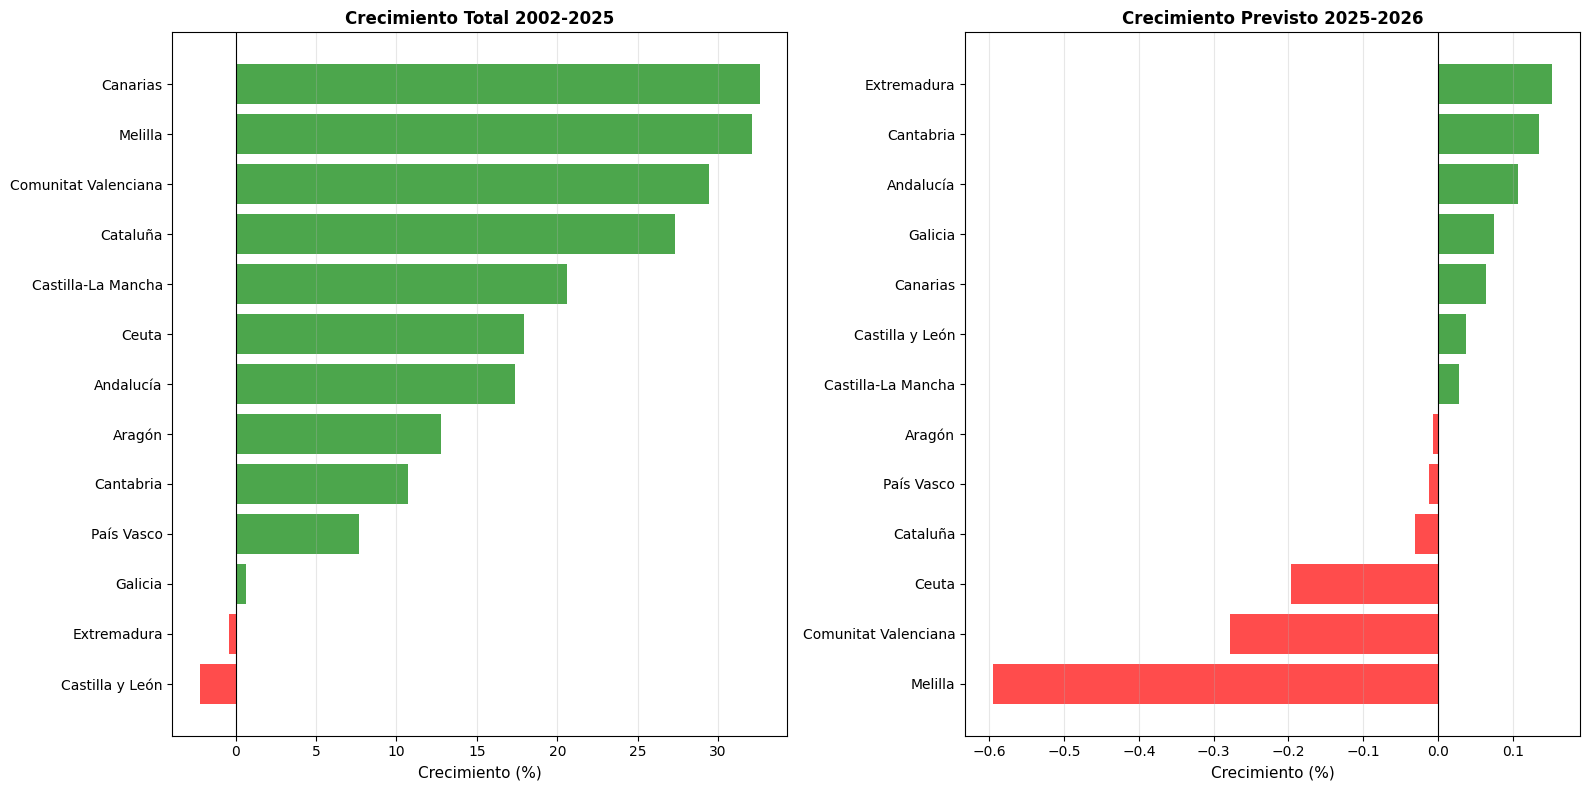

In [144]:
# Gráfico 3: Mapa de calor de crecimiento poblacional por CCAA
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 8))

# Gráfico de barras - Crecimiento 2002-2025
df_tasas_sorted = df_tasas.sort_values('crecimiento_total_2002_2025', ascending=True)
colors1 = ['green' if x > 0 else 'red' for x in df_tasas_sorted['crecimiento_total_2002_2025']]
ax1.barh(df_tasas_sorted['ccaa_pretty'], df_tasas_sorted['crecimiento_total_2002_2025'], 
         color=colors1, alpha=0.7)
ax1.axvline(0, color='black', linewidth=0.8)
ax1.set_xlabel('Crecimiento (%)', fontsize=11)
ax1.set_title('Crecimiento Total 2002-2025', fontsize=12, fontweight='bold')
ax1.grid(axis='x', alpha=0.3)

# Gráfico de barras - Predicción 2025-2026
df_tasas_sorted2 = df_tasas.sort_values('crecimiento_2025_2026', ascending=True)
colors2 = ['green' if x > 0 else 'red' for x in df_tasas_sorted2['crecimiento_2025_2026']]
ax2.barh(df_tasas_sorted2['ccaa_pretty'], df_tasas_sorted2['crecimiento_2025_2026'], 
         color=colors2, alpha=0.7)
ax2.axvline(0, color='black', linewidth=0.8)
ax2.set_xlabel('Crecimiento (%)', fontsize=11)
ax2.set_title('Crecimiento Previsto 2025-2026', fontsize=12, fontweight='bold')
ax2.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.show()


In [145]:
# ====================================================================================================
# EXPORTAR TODAS LAS TABLAS A EXCEL CON INFORMACIÓN AMPLIADA
# ====================================================================================================

# Crear archivo Excel con múltiples hojas
nombre_archivo = "Resultados_Predicciones_Poblacion_Completo.xlsx"

with pd.ExcelWriter(nombre_archivo, engine='openpyxl') as writer:
    
    # HOJA 1: PREVISIONES 2026 - Comparativa con años anteriores
    df_export_prev = df_total[df_total['ccaa'] != 'nacional'].copy()
    
    # Obtener datos de 2023, 2024, 2025 para comparación usando df_historico_agg
    años_comparacion = [2023, 2024, 2025]
    for año in años_comparacion:
        if año in df_historico_agg.columns:
            df_año_data = df_historico_agg[año].reset_index()
            df_año_data.columns = ['ccaa', f'Población {año}']
            df_export_prev = df_export_prev.merge(df_año_data, on='ccaa', how='left')
    
    df_export_prev['Población 2026 (Predicción)'] = df_export_prev['pred_poblacion_2026']
    
    # Calcular incrementos solo si tenemos los datos de 2025
    if 'Población 2025' in df_export_prev.columns:
        df_export_prev['Incremento 2025-2026'] = df_export_prev['Población 2026 (Predicción)'] - df_export_prev['Población 2025']
        df_export_prev['% Crecimiento 2025-2026'] = ((df_export_prev['Población 2026 (Predicción)'] / df_export_prev['Población 2025'] - 1) * 100).round(2)
    
    # Seleccionar columnas que existen
    columnas_prev = ['ccaa_pretty']
    for año in años_comparacion:
        col_name = f'Población {año}'
        if col_name in df_export_prev.columns:
            columnas_prev.append(col_name)
    
    columnas_prev.extend(['Población 2026 (Predicción)'])
    if 'Incremento 2025-2026' in df_export_prev.columns:
        columnas_prev.extend(['Incremento 2025-2026', '% Crecimiento 2025-2026'])
    
    df_export_prev = df_export_prev[columnas_prev].copy()
    # Renombrar la primera columna
    df_export_prev = df_export_prev.rename(columns={'ccaa_pretty': 'CCAA'})
    df_export_prev = df_export_prev.sort_values('Población 2026 (Predicción)', ascending=False)
    df_export_prev.to_excel(writer, sheet_name='Previsiones_2026', index=False)
    
    # HOJA 2: RATIOS MÚLTIPLES por CCAA
    df_export_ratios = df_total[df_total['ccaa'] != 'nacional'].copy()
    
    # Ratio Hombres/Mujeres
    df_hm = df_ratio[df_ratio['ccaa'] != 'nacional'][['ccaa', 'ratio']].copy()
    df_hm.columns = ['ccaa', 'Ratio H/M']
    df_export_ratios = df_export_ratios.merge(df_hm, on='ccaa', how='left')
    
    # Ratio Españoles/Extranjeros - Usar EXACTAMENTE la misma lógica que el gráfico nacional
    # Filtrar: total sexo, todas las edades, por CCAA (excluir nacional)
    df_nac_por_ccaa = df_pred_2026[
        (df_pred_2026["key"].str.contains("total_todas_las_edades_")) & 
        (df_pred_2026["ccaa"] != "nacional")
    ].copy()
    
    # Agrupar españoles por CCAA (nacionalidad == 'espanola')
    df_esp = df_nac_por_ccaa[df_nac_por_ccaa['nacionalidad'] == 'espanola'].groupby('ccaa')['pred_poblacion_2026'].sum().reset_index()
    df_esp.columns = ['ccaa', 'Españoles']
    
    # Calcular total de extranjeros por CCAA (todas las nacionalidades EXCEPTO 'espanola' y 'total')
    df_ext = df_nac_por_ccaa[
        (~df_nac_por_ccaa['nacionalidad'].isin(['espanola', 'total']))
    ].groupby('ccaa')['pred_poblacion_2026'].sum().reset_index()
    df_ext.columns = ['ccaa', 'Extranjeros']
    
    df_export_ratios = df_export_ratios.merge(df_esp, on='ccaa', how='left')
    df_export_ratios = df_export_ratios.merge(df_ext, on='ccaa', how='left')
    
    # Calcular ratios con manejo de valores faltantes
    df_export_ratios['Españoles'] = df_export_ratios['Españoles'].fillna(0)
    df_export_ratios['Extranjeros'] = df_export_ratios['Extranjeros'].fillna(0)
    
    # Ratio Españoles/Extranjeros (evitar división por cero)
    df_export_ratios['Ratio Españoles/Extranjeros'] = df_export_ratios.apply(
        lambda row: round(row['Españoles'] / row['Extranjeros'], 2) if row['Extranjeros'] > 0 else 0, axis=1
    )
    
    # % Españoles y Extranjeros
    df_export_ratios['% Españoles'] = ((df_export_ratios['Españoles'] / df_export_ratios['pred_poblacion_2026']) * 100).round(2)
    df_export_ratios['% Extranjeros'] = ((df_export_ratios['Extranjeros'] / df_export_ratios['pred_poblacion_2026']) * 100).round(2)
    
    # Ratio Población/Total Nacional
    total_nacional = df_total[df_total['ccaa'] == 'nacional']['pred_poblacion_2026'].values[0]
    df_export_ratios['% del Total Nacional'] = ((df_export_ratios['pred_poblacion_2026'] / total_nacional) * 100).round(2)
    
    columnas_ratios = ['ccaa_pretty', 'pred_poblacion_2026', 'Ratio H/M', 'Españoles', 'Extranjeros', 
                       'Ratio Españoles/Extranjeros', '% Españoles', '% Extranjeros', '% del Total Nacional']
    df_export_ratios = df_export_ratios[columnas_ratios].copy()
    df_export_ratios.columns = ['CCAA', 'Población Total 2026', 'Ratio H/M', 'Españoles', 'Extranjeros',
                                 'Ratio Españoles/Extranjeros', '% Españoles', '% Extranjeros', '% del Total Nacional']
    df_export_ratios = df_export_ratios.sort_values('Población Total 2026', ascending=False)
    df_export_ratios.to_excel(writer, sheet_name='Ratios_Multiples', index=False)
    
    # HOJA 3: TASAS DE CRECIMIENTO DETALLADAS
    df_export_tasas_det = pd.DataFrame()
    
    for ccaa in df_historico_agg.index:
        if ccaa == 'nacional':
            continue
            
        data = df_historico_agg.loc[ccaa]
        
        # Población por años clave
        pob_2002 = data[2002] if 2002 in data.index else None
        pob_2010 = data[2010] if 2010 in data.index else None
        pob_2020 = data[2020] if 2020 in data.index else None
        pob_2025 = data[2025] if 2025 in data.index else None
        pob_2026 = data[2026] if 2026 in data.index else None
        
        # Calcular tasas
        tasa_2002_2010 = ((pob_2010 / pob_2002 - 1) * 100) if pob_2002 and pob_2010 else None
        tasa_2010_2020 = ((pob_2020 / pob_2010 - 1) * 100) if pob_2010 and pob_2020 else None
        tasa_2020_2025 = ((pob_2025 / pob_2020 - 1) * 100) if pob_2020 and pob_2025 else None
        tasa_2025_2026 = ((pob_2026 / pob_2025 - 1) * 100) if pob_2025 and pob_2026 else None
        tasa_total = ((pob_2026 / pob_2002 - 1) * 100) if pob_2002 and pob_2026 else None
        
        df_export_tasas_det = pd.concat([df_export_tasas_det, pd.DataFrame({
            'ccaa': [ccaa],
            'Población 2002': [pob_2002],
            'Población 2010': [pob_2010],
            'Población 2020': [pob_2020],
            'Población 2025': [pob_2025],
            'Población 2026': [pob_2026],
            'Crecimiento 2002-2010 (%)': [round(tasa_2002_2010, 2) if tasa_2002_2010 else None],
            'Crecimiento 2010-2020 (%)': [round(tasa_2010_2020, 2) if tasa_2010_2020 else None],
            'Crecimiento 2020-2025 (%)': [round(tasa_2020_2025, 2) if tasa_2020_2025 else None],
            'Crecimiento 2025-2026 (%)': [round(tasa_2025_2026, 2) if tasa_2025_2026 else None],
            'Crecimiento Total 2002-2026 (%)': [round(tasa_total, 2) if tasa_total else None]
        })], ignore_index=True)
    
    # Agregar nombres bonitos
    df_export_tasas_det['CCAA'] = df_export_tasas_det['ccaa'].map(pretty)
    columnas_order = ['CCAA', 'Población 2002', 'Población 2010', 'Población 2020', 'Población 2025', 'Población 2026',
                      'Crecimiento 2002-2010 (%)', 'Crecimiento 2010-2020 (%)', 'Crecimiento 2020-2025 (%)',
                      'Crecimiento 2025-2026 (%)', 'Crecimiento Total 2002-2026 (%)']
    df_export_tasas_det = df_export_tasas_det[columnas_order]
    df_export_tasas_det = df_export_tasas_det.sort_values('Crecimiento 2025-2026 (%)', ascending=False, na_position='last')
    df_export_tasas_det.to_excel(writer, sheet_name='Tasas_Crecimiento_Detalladas', index=False)
    
    # HOJA 4: EVOLUCIÓN DE LA POBLACIÓN (Histórico + Proyección)
    # Transponer df_historico_agg para que las CCAA sean columnas y los años filas
    df_export_evol = df_historico_agg.T.copy()
    
    # Renombrar columnas CCAA con nombres bonitos ANTES de reset_index
    col_rename = {ccaa: pretty.get(ccaa, ccaa) for ccaa in df_historico_agg.index if ccaa != 'nacional'}
    if 'nacional' in df_export_evol.columns:
        col_rename['nacional'] = 'Nacional'
    df_export_evol = df_export_evol.rename(columns=col_rename)
    
    # Ahora hacer reset_index y renombrar la columna del índice
    df_export_evol = df_export_evol.reset_index()
    # La primera columna (del índice) contiene los años
    df_export_evol.columns.values[0] = 'Año'
    
    # Reordenar para poner Nacional al principio si existe
    if 'Nacional' in df_export_evol.columns:
        cols_order = ['Año', 'Nacional'] + [col for col in df_export_evol.columns if col not in ['Año', 'Nacional']]
        df_export_evol = df_export_evol[cols_order]
    
    df_export_evol = df_export_evol.sort_values('Año')
    df_export_evol.to_excel(writer, sheet_name='Evolucion_Poblacion', index=False)
    
    # HOJA 5: Predicciones completas (df_pred_2026 con todas las combinaciones)
    df_export_pred = df_pred_2026[['key', 'pred_poblacion_2026', 'ccaa', 'nacionalidad']].copy()
    df_export_pred.columns = ['Clave', 'Población Predicha 2026', 'CCAA', 'Nacionalidad']
    df_export_pred.to_excel(writer, sheet_name='Predicciones_Completas', index=False)
    
    # HOJA 6: KPI 1 - Población por CCAA (solo total)
    df_export_ccaa = df_total[df_total['ccaa'] != 'nacional'].copy()
    df_export_ccaa = df_export_ccaa[['ccaa_pretty', 'pred_poblacion_2026']].copy()
    df_export_ccaa.columns = ['CCAA', 'Población Predicha 2026']
    df_export_ccaa = df_export_ccaa.sort_values('Población Predicha 2026', ascending=False)
    df_export_ccaa.to_excel(writer, sheet_name='KPI1_Poblacion_CCAA', index=False)
    
    # HOJA 7: KPI 2 - Ratio Hombres/Mujeres por CCAA
    df_export_ratio = df_ratio[df_ratio['ccaa'] != 'nacional'].copy()
    df_export_ratio = df_export_ratio[['ccaa_pretty', 'hombres', 'mujeres', 'ratio']].copy()
    df_export_ratio.columns = ['CCAA', 'Hombres', 'Mujeres', 'Ratio H/M']
    df_export_ratio = df_export_ratio.sort_values('Ratio H/M', ascending=False)
    df_export_ratio.to_excel(writer, sheet_name='KPI2_Ratio_Genero', index=False)
    
    # HOJA 8: KPI 3 - Población por nacionalidad (Nacional)
    if 'df_nac_sin_total' in locals():
        df_export_nac = df_nac_sin_total[df_nac_sin_total['pred_poblacion_2026'] > 0].copy()
        df_export_nac = df_export_nac[['nac_pretty', 'pred_poblacion_2026']].copy()
        df_export_nac.columns = ['Nacionalidad', 'Población Predicha 2026']
        df_export_nac = df_export_nac.sort_values('Población Predicha 2026', ascending=False)
        
        # Agregar porcentaje
        total_nacional = df_total[df_total['ccaa'] == 'nacional']['pred_poblacion_2026'].values[0]
        df_export_nac['Porcentaje'] = (df_export_nac['Población Predicha 2026'] / total_nacional * 100).round(2)
        
        df_export_nac.to_excel(writer, sheet_name='KPI3_Nacionalidad', index=False)
    
    # HOJA 9: KPI 6 - Distribución por edad (Nacional)
    if 'df_edad' in locals():
        # Filtrar solo datos nacionales y agrupar por grupo de edad
        df_export_edad = df_edad[df_edad['ccaa'] == 'nacional'].copy()
        df_export_edad = df_export_edad.groupby('grupo_edad')['pred_poblacion_2026'].sum().reset_index()
        df_export_edad.columns = ['Grupo de Edad', 'Población Predicha 2026']
        df_export_edad = df_export_edad.sort_values('Población Predicha 2026', ascending=False)
        df_export_edad.to_excel(writer, sheet_name='KPI6_Edad', index=False)
    
    # HOJA 10: KPI 7 - Dashboard resumen por CCAA
    if 'dashboard_final' in locals():
        df_export_dashboard = dashboard_final.copy()
        df_export_dashboard.to_excel(writer, sheet_name='KPI7_Dashboard_CCAA', index=False)

print(f"✅ Archivo '{nombre_archivo}' generado exitosamente con múltiples hojas")
print("\n📊 HOJAS INCLUIDAS:")
print("  1. Previsiones_2026 - Comparativa 2023-2026 con tasas de crecimiento")
print("  2. Ratios_Multiples - Ratios H/M, Españoles/Extranjeros, % Total Nacional")
print("  3. Tasas_Crecimiento_Detalladas - Evolución por décadas y proyección 2026")
print("  4. Evolucion_Poblacion - Serie temporal completa por CCAA (2002-2026)")
print("  5. Predicciones_Completas - Todas las predicciones por clave")
print("  6. KPI1_Poblacion_CCAA - Población total por comunidad autónoma")
print("  7. KPI2_Ratio_Genero - Ratio hombres/mujeres por CCAA")
print("  8. KPI3_Nacionalidad - Población por nacionalidad")
print("  9. KPI6_Edad - Distribución por grupos de edad")
print(" 10. KPI7_Dashboard_CCAA - Dashboard resumen por CCAA")

✅ Archivo 'Resultados_Predicciones_Poblacion_Completo.xlsx' generado exitosamente con múltiples hojas

📊 HOJAS INCLUIDAS:
  1. Previsiones_2026 - Comparativa 2023-2026 con tasas de crecimiento
  2. Ratios_Multiples - Ratios H/M, Españoles/Extranjeros, % Total Nacional
  3. Tasas_Crecimiento_Detalladas - Evolución por décadas y proyección 2026
  4. Evolucion_Poblacion - Serie temporal completa por CCAA (2002-2026)
  5. Predicciones_Completas - Todas las predicciones por clave
  6. KPI1_Poblacion_CCAA - Población total por comunidad autónoma
  7. KPI2_Ratio_Genero - Ratio hombres/mujeres por CCAA
  8. KPI3_Nacionalidad - Población por nacionalidad
  9. KPI6_Edad - Distribución por grupos de edad
 10. KPI7_Dashboard_CCAA - Dashboard resumen por CCAA
